# FRM Parte I avanzado, libro 1: Fundamentos de la gestión de riesgos

Versión de mayor nivel del libro 1 del programa 2026 de GARP. Cubre los 11 capítulos en el orden oficial y complementa los casos introductorios de [05_FRM](../05_FRM/01_fundamentos_gestion_riesgos.ipynb).

Cada capítulo tiene cinco partes:

1. **Idea central.** Los conceptos y fórmulas que hay que dominar, escritos para quien ya conoce lo básico.
2. **Análisis avanzado.** Una aplicación con datos reales de Chile y Estados Unidos, o una simulación cuando no hay datos públicos.
3. **Ejercicios resueltos en Python.** Algunos vienen del banco de ejercicios del proyecto frm-prep y otros son propios, de mayor dificultad.
4. **Preguntas de práctica.** Seleccionadas del banco de 1.016 preguntas de frm-prep, con la respuesta oculta. Donde el banco no cubre el capítulo, se agregan preguntas propias.
5. **Trampas frecuentes.** Los errores que el examen suele explotar.

| Código | Capítulo | Análisis avanzado |
|---|---|---|
| FRM-1 | Los fundamentos de la gestión de riesgos | La misma pérdida esperada con colas muy distintas |
| FRM-2 | Cómo gestionan las empresas el riesgo financiero | El valor de cubrirse cuando el impuesto es convexo |
| FRM-3 | La gobernanza de la gestión de riesgos | Del apetito de riesgo del directorio a los límites por mesa |
| FRM-4 | Mecanismos de transferencia del riesgo de crédito | Tramos de una CDO y el papel de la correlación |
| FRM-5 | Teoría moderna de carteras y CAPM | La cartera óptima con error de estimación |
| FRM-6 | APT y modelos multifactoriales | Riesgo sistemático e idiosincrático de las acciones del IPSA |
| FRM-7 | Principios de agregación de datos de riesgo | Control de calidad sobre datos reales de la CMF |
| FRM-8 | Gestión integral de riesgos y tendencias | Agregación de capital económico y RAROC |
| FRM-9 | Lecciones de desastres financieros | Metallgesellschaft con el precio del cobre |
| FRM-10 | Anatomía de la gran crisis financiera | La crisis de 2007 a 2009 en datos |
| FRM-11 | Código de conducta de GARP | Dilemas resueltos |

Las fórmulas nuevas están en el módulo `frm_avanzado` del paquete, con pruebas que reproducen las respuestas del banco de ejercicios de frm-prep y ejemplos publicados en Hull y por el Comité de Basilea.

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from dsaplicado import datos, frm, frm_avanzado as fa, portafolio as pf
from dsaplicado.graficos import COLORES, NEUTRO, TINTA_SECUNDARIA, TINTA_TENUE, aplicar_estilo, eje_porcentaje

aplicar_estilo()
pd.set_option("display.float_format", "{:,.4f}".format)
RAIZ = datos.raiz_repositorio()
DATOS = RAIZ / "datos"
FIGURAS = RAIZ / "06_FRM_advance" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

precios = datos.cargar_precios(DATOS / "precios_ipsa.csv", {**datos.ACCIONES_IPSA, **datos.BENCHMARK_IPSA},
                               "2019-01-01", "2026-09-01").ffill()
acciones = list(datos.ACCIONES_IPSA.values())
retornos = pf.retornos_simples(precios).dropna()

# El dólar observado y el cobre de un día reflejan cotizaciones del día hábil anterior:
# se adelantan un día para alinearlos con los precios de las acciones.
dolar = datos.cargar_indicador(DATOS / "dolar_historico.csv", "dolar", range(2000, 2027))
cobre = datos.cargar_indicador(DATOS / "libra_cobre_historico.csv", "libra_cobre", range(2012, 2027))
dolar_alineado, cobre_alineado = dolar.shift(-1), cobre.shift(-1)

tpm = datos.cargar_indicador(DATOS / "tpm_historico.csv", "tpm", range(2001, 2027))
tpm = tpm.mask(tpm < 0.25).ffill() / 100
rf_anual = float(tpm.loc[retornos.index[0]:retornos.index[-1]].mean())
print(f"Acciones: {len(retornos):,} días, de {retornos.index[0]:%m-%Y} a {retornos.index[-1]:%m-%Y}. TPM promedio: {rf_anual:.2%}")
print(f"Dólar: {dolar.index[0]:%Y} a {dolar.index[-1]:%d-%m-%Y}, último {dolar.iloc[-1]:,.2f}. Cobre: último {cobre.iloc[-1]:.2f} USD/lb")

Acciones: 1,908 días, de 01-2019 a 08-2026. TPM promedio: 4.90%
Dólar: 2000 a 24-09-2026, último 959.39. Cobre: último 6.66 USD/lb


## FRM-1. Los fundamentos de la gestión de riesgos

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Riesgo e incertidumbre.** El riesgo, en el sentido de Knight, tiene probabilidades medibles; la incertidumbre no. Muchos eventos de cola están más cerca de la incertidumbre, y por eso los modelos se complementan con pruebas de estrés.
- **Pérdida esperada e inesperada.** La pérdida esperada (EL) es un costo del negocio: se cubre con provisiones y se incorpora al precio. La pérdida inesperada (UL) es la dispersión alrededor de la media y se cubre con capital:

$$\text{EL} = PD \cdot LGD \cdot EAD, \qquad \text{capital económico} = \text{VaR}_{99,9\%} - \text{EL}$$

- **Tipos de riesgo.** Mercado, crédito, liquidez (de financiamiento y de mercado), operacional, de negocio, estratégico y reputacional. Interactúan: una pérdida de mercado puede gatillar un problema de liquidez de financiamiento.
- **Proceso de gestión.** Identificar, medir, gestionar y monitorear. Ante un riesgo hay cuatro respuestas: evitarlo, retenerlo, mitigarlo o transferirlo.
- **Apetito de riesgo.** Es cuánto riesgo está dispuesta a asumir la organización para lograr sus objetivos. La tolerancia fija la desviación aceptable respecto de ese apetito.

El punto de mayor nivel: **la media no describe el riesgo.** Dos carteras con la misma pérdida esperada pueden necesitar capitales muy distintos, según la correlación entre sus exposiciones.

### Análisis avanzado: la misma pérdida esperada con colas muy distintas

Se simula una cartera de 500 créditos iguales, con PD de 2% y LGD de 45%, con el modelo de un factor de Vasicek: todos los deudores dependen de un factor común de la economía con correlación ρ. La pérdida esperada es la misma para cualquier ρ, 0,9% de la cartera, pero la cola cambia por completo.

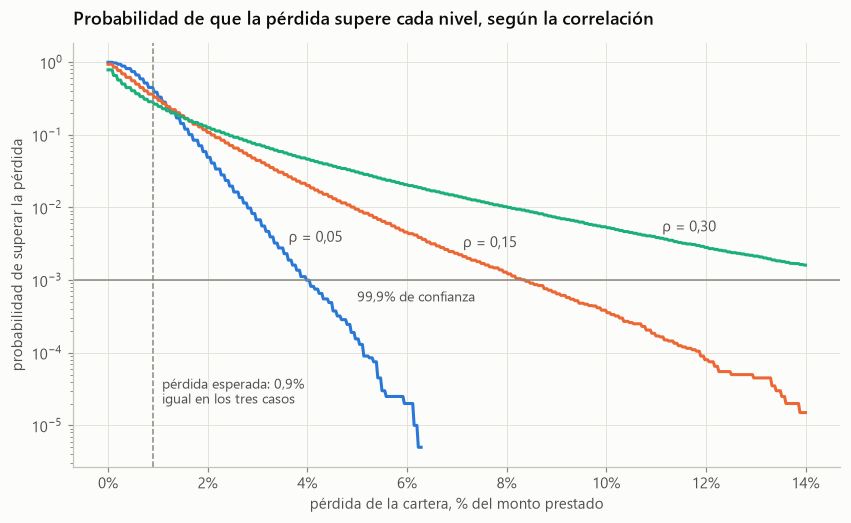

,pérdida esperada,desviación estándar,"VaR 99,9%",capital económico,capital de Vasicek asintótico
ρ = 0.05,0.90%,0.59%,3.96%,3.06%,2.75%
ρ = 0.15,0.90%,1.03%,8.37%,7.47%,7.03%
ρ = 0.30,0.90%,1.64%,15.75%,14.85%,14.08%


In [2]:
pd_, lgd, n_creditos = 0.02, 0.45, 500
correlaciones = [0.05, 0.15, 0.30]
perdidas = {rho: fa.perdidas_copula_gaussiana(pd_, rho, n_creditos, simulaciones=200_000, lgd=lgd, semilla=1)
            for rho in correlaciones}

filas = {}
for rho, l in perdidas.items():
    var999 = np.quantile(l, 0.999)
    filas[f"ρ = {rho:.2f}"] = {
        "pérdida esperada": l.mean(), "desviación estándar": l.std(), "VaR 99,9%": var999,
        "capital económico": var999 - l.mean(),
        "capital de Vasicek asintótico": lgd * (frm.tasa_default_peor_caso(pd_, rho) - pd_),
    }
tabla_capital = pd.DataFrame(filas).T

fig, ax = plt.subplots(figsize=(9, 5))
umbrales = np.linspace(0, 0.14, 500)
for color, (rho, l) in zip(COLORES, perdidas.items()):
    orden = np.sort(l)
    cola = 1 - np.searchsorted(orden, umbrales, side="right") / len(orden)
    ax.semilogy(umbrales, np.where(cola > 0, cola, np.nan), color=color, linewidth=2)
    x_etiqueta = {0.05: 0.035, 0.15: 0.07, 0.30: 0.11}[rho]
    y_etiqueta = 1 - np.searchsorted(orden, x_etiqueta, side="right") / len(orden)
    ax.annotate(f"ρ = {rho:.2f}".replace(".", ","), (x_etiqueta, y_etiqueta), xytext=(4, 4), textcoords="offset points", color=TINTA_SECUNDARIA)
ax.axvline(pd_ * lgd, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("pérdida esperada: 0,9%\nigual en los tres casos", (pd_ * lgd, 2e-5), xytext=(6, 0), textcoords="offset points",
            color=TINTA_SECUNDARIA, fontsize=9)
ax.axhline(0.001, color=TINTA_TENUE, linewidth=1)
ax.annotate("99,9% de confianza", (0.05, 0.001), xytext=(0, -14), textcoords="offset points", ha="left",
            color=TINTA_SECUNDARIA, fontsize=9)
eje_porcentaje(ax, "x")
ax.set_xlabel("pérdida de la cartera, % del monto prestado")
ax.set_ylabel("probabilidad de superar la pérdida")
ax.set_title("Probabilidad de que la pérdida supere cada nivel, según la correlación")
fig.savefig(FIGURAS / "colas_credito.png", bbox_inches="tight")
plt.show()
tabla_capital.map("{:.2%}".format)

**Lectura.**

- **La media es la misma; la cola, no.** La pérdida esperada es 0,9% en los tres casos, pero el VaR al 99,9% sube de 4,0% con ρ = 0,05 a 15,8% con ρ = 0,30. El capital económico se multiplica casi por cinco, de 3,1% a 14,9% de la cartera.
- **La fórmula asintótica de Vasicek queda cerca de la simulación:** 2,8%, 7,0% y 14,1%, algo bajo los valores simulados. La diferencia es el riesgo idiosincrático que todavía tiene una cartera de 500 créditos. Basilea usa la fórmula asintótica, que supone una cartera infinitamente granular.
- **La correlación con el ciclo, no la PD, es lo que más mueve el capital.** Por eso el libro 4 le dedica tanto espacio.

### Ejercicios resueltos

**Ejercicio 1.1. Criterio safety-first de Roy** *(banco de ejercicios de frm-prep)*

El retorno mínimo aceptable de un inversionista es 3%. La cartera A espera 10% con desviación estándar de 12%. Calcula el ratio safety-first. Como extensión, compárala con una cartera B que espera 8% con desviación de 7% y calcula, suponiendo normalidad, la probabilidad de que cada una rinda menos que el umbral.

In [3]:
umbral = 0.03
carteras = {"A": (0.10, 0.12), "B": (0.08, 0.07)}
for nombre, (media, desv) in carteras.items():
    sf = fa.ratio_safety_first(media, desv, umbral)
    print(f"Cartera {nombre}: SFRatio = ({media:.0%} - {umbral:.0%}) / {desv:.0%} = {sf:.3f};"
          f" P(R < {umbral:.0%}) = N(-{sf:.3f}) = {stats.norm.cdf(-sf):.1%}")
print("Respuesta: el ratio de A es 0,583. Se elige la cartera con el mayor ratio, B, porque minimiza la probabilidad de no alcanzar el umbral.")

Cartera A: SFRatio = (10% - 3%) / 12% = 0.583; P(R < 3%) = N(-0.583) = 28.0%
Cartera B: SFRatio = (8% - 3%) / 7% = 0.714; P(R < 3%) = N(-0.714) = 23.8%
Respuesta: el ratio de A es 0,583. Se elige la cartera con el mayor ratio, B, porque minimiza la probabilidad de no alcanzar el umbral.


**Ejercicio 1.2. Precio ajustado por riesgo de un préstamo** *(ejercicio propio)*

Un banco presta $1.000 millones a un año a una empresa con PD de 1,5%, LGD de 40% y correlación de activos de 0,18. Se financia al 5%, tiene costos operativos de 0,5% del monto y exige 12% de retorno sobre el capital económico, que mide como la pérdida al 99,9% del modelo de Vasicek menos la pérdida esperada. ¿Qué tasa mínima debe cobrar?

La parte del préstamo financiada con capital cuesta el retorno exigido en vez del costo de fondos, así que la tasa mínima es el costo de fondos, más los costos operativos, más la pérdida esperada, más el sobrecosto del capital.

In [4]:
ead, pd_c, lgd_c, rho_c = 1_000.0, 0.015, 0.40, 0.18
costo_fondos, costo_operativo, retorno_exigido = 0.05, 0.005, 0.12

el = frm.perdida_esperada(pd_c, lgd_c, ead)
peor_caso = frm.tasa_default_peor_caso(pd_c, rho_c, 0.999)
capital = lgd_c * (peor_caso - pd_c) * ead
componentes = {
    "costo de fondos": costo_fondos,
    "costos operativos": costo_operativo,
    "pérdida esperada": el / ead,
    "sobrecosto del capital": (retorno_exigido - costo_fondos) * capital / ead,
}
print(f"Pérdida esperada: {el:.1f} millones. Tasa de incumplimiento en el peor caso: {peor_caso:.2%}. Capital: {capital:.1f} millones ({capital/ead:.2%}).")
for nombre, valor in componentes.items():
    print(f"  {nombre:<24}{valor:.3%}")
print(f"Respuesta: tasa mínima = {sum(componentes.values()):.2%}")

Pérdida esperada: 6.0 millones. Tasa de incumplimiento en el peor caso: 17.14%. Capital: 62.6 millones (6.26%).
  costo de fondos         5.000%
  costos operativos       0.500%
  pérdida esperada        0.600%
  sobrecosto del capital  0.438%
Respuesta: tasa mínima = 6.54%


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Una cartera de crédito tiene una pérdida esperada de \$2M y una pérdida en el peor caso al 99.9% de \$8M. El capital económico (para cubrir la pérdida inesperada) es:

- **A.** $8M
- **B.** $6M
- **C.** $2M
- **D.** $10M

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** El capital económico cubre la pérdida inesperada $=$ pérdida del peor caso $-$ pérdida esperada $= 8 - 2 = \$6\text{M}$ (la EL se cubre con provisiones).

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

En el sentido de Knight, el "riesgo" difiere de la "incertidumbre" en que el riesgo:

- **A.** aplica solo a exposiciones de crédito.
- **B.** no puede medirse en absoluto.
- **C.** involucra resultados con probabilidades conocidas o estimables, mientras que la incertidumbre involucra resultados cuyas probabilidades no pueden cuantificarse de forma confiable.
- **D.** siempre es mayor que la incertidumbre.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Frank Knight distinguió el riesgo medible (distribuciones de probabilidad conocidas) de la verdadera incertidumbre (probabilidades incognoscibles o inmensurables). Muchos eventos de cola se acercan más a la incertidumbre knightiana, lo que limita los modelos puramente estadísticos y motiva el stress testing y el juicio.

</details>

### Trampas frecuentes

- La pérdida esperada no es capital: se cubre con provisiones y precio. El capital cubre la inesperada.
- Las pérdidas inesperadas no se suman entre carteras: dependen de la correlación, igual que el VaR.
- Riesgo no es lo mismo que incertidumbre. Si la pregunta menciona probabilidades imposibles de estimar, apunta a Knight.
- Retener un riesgo es una decisión válida cuando cubrirlo cuesta más de lo que protege.

## FRM-2. Cómo gestionan las empresas el riesgo financiero

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Modigliani-Miller.** En mercados perfectos, cubrirse no crea valor: los accionistas pueden diversificar por su cuenta. La cobertura crea valor solo por imperfecciones del mercado.
- **Fuentes de valor.** Impuestos convexos, costos de dificultades financieras, sobreendeudamiento que lleva a subinvertir (*debt overhang*), capacidad de deuda, asimetrías de información e incentivos de los gerentes.
- **Instrumentos.** Los forwards fijan el precio y eliminan también la ganancia al alza. Las opciones protegen a la baja y conservan el alza a cambio de una prima. Los swaps transforman flujos variables en fijos.
- **Coberturas operativas y financieras.** Producir en el país donde se vende es una cobertura natural del tipo de cambio.
- **Riesgos de la cobertura.** Riesgo de base, riesgo de liquidez por los márgenes, riesgo contable y la tentación de especular.

La desigualdad de Jensen explica el argumento tributario. Si el impuesto $T(\cdot)$ es convexo, $E[T(X)] \ge T(E[X])$: reducir la varianza de la utilidad baja el impuesto esperado.

### Análisis avanzado: el valor de cubrirse cuando el impuesto es convexo

Un exportador vende USD 100 millones al año y tiene costos fijos en pesos. Paga 27% sobre la utilidad positiva y nada si pierde, un esquema convexo porque no recupera impuestos en los años malos. Si la pérdida supera $3.000 millones, además enfrenta costos de dificultades financieras equivalentes al 25% del exceso.

Los escenarios del dólar a un año vienen de las variaciones de 12 meses del dólar observado desde 2000, centradas para que el dólar esperado coincida con el forward. Así, cubrirse no cambia la utilidad esperada antes de impuestos, y cualquier diferencia se debe a la convexidad.

Spot 959.39, TPM 4.50%, tasa de EE.UU. a un año 4.49%, forward a un año 959.49. 309 escenarios.
Valor anual de cubrirse: 758 millones de pesos


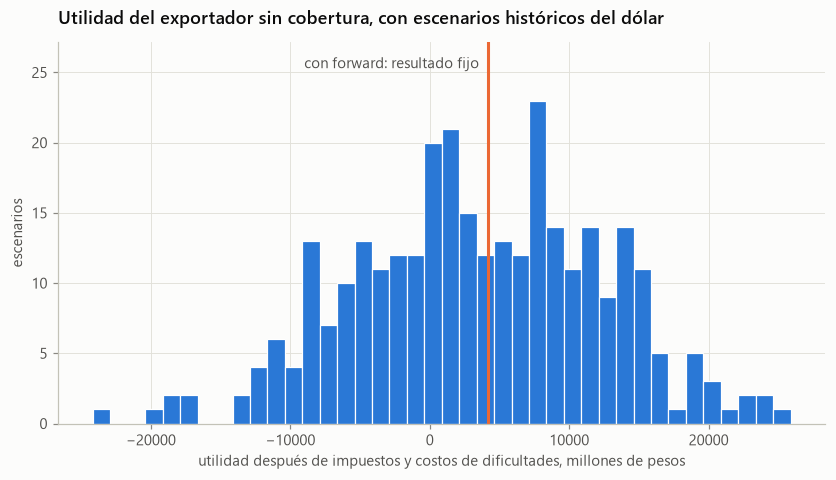

,utilidad antes de impuestos,impuesto esperado,costo de dificultades esperado,utilidad después de impuestos,probabilidad de pérdida,percentil 5% después de impuestos
sin cobertura,"5,756.9157","2,060.7331",251.2569,"3,444.9257",0.3463,"-10,616.2774"
con forward,"5,756.9157","1,554.3672",0.0000,"4,202.5484",0.0000,"4,202.5484"


In [5]:
dolar_mensual = dolar.resample("ME").last()
cambios = np.log(dolar_mensual).diff(12).dropna().to_numpy()

spot = float(dolar.iloc[-1])
r_clp = float(tpm.iloc[-1])
r_usd = float(datos.cargar_fred("DGS1", DATOS / "fred").iloc[-1]) / 100
forward = frm.precio_forward(spot, r_clp, 1.0, rendimiento=r_usd)
escenarios = forward * np.exp(cambios) / np.mean(np.exp(cambios))

ventas_usd = 100.0                       # millones de USD
costos = 0.94 * ventas_usd * forward     # millones de pesos: margen de 6% al tipo de cambio forward
tasa_impuesto, umbral_dificultad, costo_dificultad = 0.27, 3_000.0, 0.25

def resultado(utilidad):
    impuesto = tasa_impuesto * np.maximum(utilidad, 0)
    dificultad = costo_dificultad * np.maximum(-utilidad - umbral_dificultad, 0)
    return impuesto, dificultad, utilidad - impuesto - dificultad

sin_cobertura = ventas_usd * escenarios - costos
con_forward = np.full_like(sin_cobertura, ventas_usd * forward - costos)
filas = {}
for nombre, utilidad in [("sin cobertura", sin_cobertura), ("con forward", con_forward)]:
    impuesto, dificultad, final = resultado(utilidad)
    filas[nombre] = {"utilidad antes de impuestos": utilidad.mean(), "impuesto esperado": impuesto.mean(),
                     "costo de dificultades esperado": dificultad.mean(), "utilidad después de impuestos": final.mean(),
                     "probabilidad de pérdida": (utilidad < 0).mean(), "percentil 5% después de impuestos": np.quantile(final, 0.05)}
tabla_cobertura = pd.DataFrame(filas).T
valor_cobertura = tabla_cobertura.loc["con forward", "utilidad después de impuestos"] - tabla_cobertura.loc["sin cobertura", "utilidad después de impuestos"]
print(f"Spot {spot:,.2f}, TPM {r_clp:.2%}, tasa de EE.UU. a un año {r_usd:.2%}, forward a un año {forward:,.2f}. {len(escenarios)} escenarios.")
print(f"Valor anual de cubrirse: {valor_cobertura:,.0f} millones de pesos")

fig, ax = plt.subplots(figsize=(9, 4.5))
alturas, *_ = ax.hist(resultado(sin_cobertura)[2], bins=40, color=COLORES[0], edgecolor="white", linewidth=0.8)
fijo = resultado(con_forward)[2][0]
ax.set_ylim(0, alturas.max() * 1.18)
ax.axvline(fijo, color=COLORES[1], linewidth=2)
ax.annotate("con forward: resultado fijo", (fijo, alturas.max() * 1.1), xytext=(-6, 0), textcoords="offset points",
            ha="right", color=TINTA_SECUNDARIA)
ax.set_xlabel("utilidad después de impuestos y costos de dificultades, millones de pesos")
ax.set_ylabel("escenarios")
ax.set_title("Utilidad del exportador sin cobertura, con escenarios históricos del dólar")
plt.show()
tabla_cobertura

**Lectura.**

- **La cobertura no cambia la utilidad esperada antes de impuestos,** 5.757 millones en ambos casos, pero sube la utilidad esperada después de impuestos en 758 millones al año. De eso, 506 millones vienen de pagar menos impuesto esperado y 251 de evitar los costos de dificultades financieras.
- **Sin cobertura, la empresa pierde en 35% de los escenarios,** y en el 5% peor pierde más de 10.600 millones después de impuestos.
- **Es la desigualdad de Jensen:** con un impuesto convexo, suavizar la utilidad baja el impuesto promedio. En un mundo sin impuestos ni costos de quiebra, la diferencia sería cero, como dice Modigliani-Miller.
- **Hoy el forward casi iguala al spot** porque la TPM y la tasa a un año de EE.UU. están ambas cerca de 4,5%. Cuando la tasa chilena es mayor, el forward queda sobre el spot y el exportador cubierto recibe además ese diferencial.

### Ejercicios resueltos

**Ejercicio 2.1. Impuesto convexo** *(ejercicio propio)*

Una empresa gana 100 o pierde 50 con igual probabilidad. Paga 30% sobre las utilidades positivas y nada sobre las pérdidas. Si se cubre, gana 25 con certeza, la misma utilidad esperada. ¿Cuánto impuesto esperado ahorra la cobertura?

In [6]:
tasa = 0.30
sin = 0.5 * tasa * max(100, 0) + 0.5 * tasa * max(-50, 0)
con = tasa * 25
print(f"Utilidad esperada sin cobertura: {0.5 * 100 + 0.5 * -50:.0f}; con cobertura: 25")
print(f"Impuesto esperado sin cobertura: {sin:.1f}; con cobertura: {con:.1f}")
print(f"Respuesta: la cobertura ahorra {sin - con:.1f} de impuesto esperado, y ese ahorro es valor para el accionista.")

Utilidad esperada sin cobertura: 25; con cobertura: 25
Impuesto esperado sin cobertura: 15.0; con cobertura: 7.5
Respuesta: la cobertura ahorra 7.5 de impuesto esperado, y ese ahorro es valor para el accionista.


**Ejercicio 2.2. Forward frente a opción de venta** *(ejercicio propio)*

El exportador quiere proteger USD 10 millones a un año. Puede vender un forward o comprar una put con strike igual al spot, valorada con Garman-Kohlhagen usando la volatilidad del dólar de los últimos dos años. Compara los pesos que recibe en cinco escenarios del dólar, con la prima pagada hoy y capitalizada a la TPM.

In [7]:
nominal = 10.0
vol = float(np.log(dolar).diff().loc[dolar.index[-1] - pd.DateOffset(years=2):].std() * np.sqrt(252))
prima = frm.black_scholes(spot, spot, r_clp, vol, 1.0, "put", q=r_usd)
escenarios_st = spot * np.array([0.85, 0.95, 1.00, 1.05, 1.15])
tabla = pd.DataFrame({
    "sin cobertura": nominal * escenarios_st,
    "forward": nominal * forward,
    "put": nominal * (np.maximum(escenarios_st, spot) - prima * np.exp(r_clp)),
}, index=pd.Index(escenarios_st.round(0), name="dólar en un año"))
print(f"Volatilidad: {vol:.1%}. Prima de la put: {prima:,.2f} pesos por dólar ({prima / spot:.2%} del spot).")
print("Pesos recibidos, en millones:")
print(tabla.round(0).to_string())
print("Respuesta: el forward fija el ingreso; la put pone un piso y conserva el alza, a cambio de la prima.")

Volatilidad: 10.7%. Prima de la put: 39.03 pesos por dólar (4.07% del spot).
Pesos recibidos, en millones:
                 sin cobertura    forward         put
dólar en un año                                      
815.0000            8,155.0000 9,595.0000  9,186.0000
911.0000            9,114.0000 9,595.0000  9,186.0000
959.0000            9,594.0000 9,595.0000  9,186.0000
1,007.0000         10,074.0000 9,595.0000  9,665.0000
1,103.0000         11,033.0000 9,595.0000 10,625.0000
Respuesta: el forward fija el ingreso; la put pone un piso y conserva el alza, a cambio de la prima.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

En un mundo con impuestos, la cobertura puede crear valor para una firma con esquemas tributarios convexos porque:

- **A.** Siempre aumenta el precio de la acción
- **B.** Aumenta las ganancias esperadas antes de impuestos
- **C.** Suavizar el ingreso imponible reduce el impuesto promedio pagado cuando la función tributaria es convexa (progresiva)
- **D.** Elimina la necesidad de financiamiento con deuda

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Con impuestos convexos (progresivos), una firma que paga impuestos sobre $100M y $0 paga más en total que una que paga sobre $50M dos veces. La cobertura suaviza el ingreso, reduciendo el impuesto promedio: una fuente real de valor en mercados imperfectos.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Una minera cubre su producción de oro para los próximos dos años usando contratos forward. Esta decisión es MENOS probable que esté motivada por:

- **A.** Cumplir covenants de acreedores que exigen flujos de caja estables
- **B.** Protegerse contra una gran pérdida que desencadenaría dificultades financieras
- **C.** Maximizar la participación al alza si los precios del oro suben
- **D.** Reducir la volatilidad del flujo de caja para apoyar el financiamiento

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Cubrir con forwards elimina tanto el riesgo a la baja COMO el potencial al alza. Una firma que quiere participación al alza debería usar opciones (comprar puts), no forwards. Las demás motivaciones son fundamentos válidos de cobertura.

</details>

### Trampas frecuentes

- Reducir la varianza por sí sola no crea valor en un mundo de Modigliani-Miller. Busca la imperfección que la pregunta menciona.
- Una empresa que quiere conservar el alza no usa forwards: usa opciones.
- Cubrir contablemente la utilidad no es lo mismo que cubrir el valor económico de la empresa.
- Una cobertura con futuros puede crear un problema de liquidez por los llamados de margen, aunque sea económicamente perfecta.

## FRM-3. La gobernanza de la gestión de riesgos

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Directorio.** Aprueba el apetito de riesgo, supervisa a la administración y debe tener miembros independientes con conocimiento de riesgos. El comité de riesgos es distinto del de auditoría.
- **Tres líneas de defensa.** La primera, las unidades de negocio, es dueña del riesgo. La segunda, gestión de riesgos y cumplimiento, fija el marco y los límites y los monitorea. La tercera, auditoría interna, da aseguramiento independiente al directorio.
- **Gerente de riesgos (CRO).** Debe ser independiente del negocio, con acceso directo al directorio.
- **Del apetito a los límites.** El apetito se traduce en límites por unidad de negocio, producto o factor. Como el riesgo no es aditivo, la suma de los límites individuales puede superar el apetito total.
- **Compensaciones.** Un bono proporcional a la ganancia y sin castigo por pérdidas es una opción de compra sobre el resultado: su valor sube con la volatilidad. El diferimiento, el *malus* y el *clawback* corrigen ese incentivo.
- **Problema de agencia.** Los gerentes (agentes) pueden perseguir intereses distintos de los accionistas (principales). Con deuda, los accionistas mismos pueden preferir más riesgo que los acreedores.

### Análisis avanzado: del apetito de riesgo a los límites por mesa

El directorio fija un apetito de VaR diario al 99% de $1.000 millones para una tesorería con tres mesas: acciones (largo $20.000 millones en el ETF IPSA), moneda (largo USD 25 millones) y tasas (un bono a 10 años con DV01 de $12 millones por punto base). Los resultados diarios históricos de cada mesa se reconstruyen con datos reales desde 2019.

Los límites se reparten en proporción al riesgo actual de cada mesa y se escalan hasta que el VaR diversificado iguale el apetito.

In [8]:
bcp = pd.read_csv(DATOS / "bcch" / "bcp_mercado_secundario.csv", index_col="fecha", parse_dates=True)
spot_actual = float(dolar.iloc[-1])
resultados_mesas = pd.concat({
    "Acciones": 20_000 * retornos["ETF IPSA"],
    "Moneda": 25 * spot_actual * dolar_alineado.pct_change(),
    "Tasas": -12 * bcp["10"].diff() * 100,
}, axis=1, sort=True).loc[retornos.index].dropna()

z = stats.norm.ppf(0.99)
var_individual = z * resultados_mesas.std()
correlacion = resultados_mesas.corr()
var_diversificado = fa.agregar_riesgos(var_individual, correlacion)

apetito = 1_000.0
escala = apetito / var_diversificado
limites = escala * var_individual
tabla_limites = pd.DataFrame({"VaR actual": var_individual, "límite asignado": limites, "uso del límite": var_individual / limites})
print(f"{len(resultados_mesas):,} días. VaR diversificado actual: {var_diversificado:,.0f}; suma de VaR individuales: {var_individual.sum():,.0f}")
print(f"Suma de los límites: {limites.sum():,.0f}, frente a un apetito de {apetito:,.0f}")
print(f"Si las correlaciones subieran a 1, el VaR con todas las mesas en su límite sería {limites.sum():,.0f}: {limites.sum() / apetito - 1:.0%} sobre el apetito.")
print("Correlaciones de los resultados diarios:")
print(correlacion.round(2).to_string())
tabla_limites

1,638 días. VaR diversificado actual: 734; suma de VaR individuales: 1,309
Suma de los límites: 1,784, frente a un apetito de 1,000
Si las correlaciones subieran a 1, el VaR con todas las mesas en su límite sería 1,784: 78% sobre el apetito.
Correlaciones de los resultados diarios:
          Acciones  Moneda   Tasas
Acciones    1.0000 -0.2500  0.1500
Moneda     -0.2500  1.0000 -0.1400
Tasas       0.1500 -0.1400  1.0000


,VaR actual,límite asignado,uso del límite
Acciones,656.2328,894.1405,0.7339
Moneda,458.4296,624.6266,0.7339
Tasas,194.6554,265.2249,0.7339


**Lectura.**

- **La diversificación entre mesas es grande.** Los VaR individuales suman 1.309 millones, pero el VaR conjunto es 734, 44% menos, sobre todo porque las acciones y el dólar se mueven en sentido contrario (correlación de −0,25).
- **Los límites suman más que el apetito.** Para que el VaR diversificado con todas las mesas en su límite sea 1.000, los límites se escalan por 1,36 y suman 1.784, 78% más que el apetito.
- **El esquema depende de las correlaciones.** Si en una crisis subieran a uno, las mesas podrían respetar sus límites y el banco igual superaría su apetito. Por eso los marcos de apetito combinan límites de VaR con límites de estrés, de concentración y de pérdida.

### Ejercicios resueltos

**Ejercicio 3.1. Límites que no suman** *(ejercicio propio)*

Dos mesas tienen límites de VaR de 60 y 80 millones, con correlación 0,3. ¿Cuál es el VaR total si ambas usan todo su límite? Si el directorio fija un apetito de 100, ¿por cuánto hay que multiplicar ambos límites?

In [9]:
limites_ej = np.array([60.0, 80.0])
correlacion_ej = np.array([[1, 0.3], [0.3, 1]])
total = fa.agregar_riesgos(limites_ej, correlacion_ej)
print(f"VaR total = raíz(60² + 80² + 2·0,3·60·80) = {total:.1f}")
print(f"Respuesta: VaR total de {total:.1f}. Para un apetito de 100 se multiplican los límites por {100 / total:.3f}: quedan en {60 * 100 / total:.1f} y {80 * 100 / total:.1f}.")

VaR total = raíz(60² + 80² + 2·0,3·60·80) = 113.5
Respuesta: VaR total de 113.5. Para un apetito de 100 se multiplican los límites por 0.881: quedan en 52.9 y 70.5.


**Ejercicio 3.2. El bono como opción de compra** *(ejercicio propio)*

Un trader cobra un bono de 20% de su resultado anual si es positivo y nada si es negativo. Su resultado es normal con media de 10 millones. Calcula el bono esperado si la desviación estándar es 20, 40 u 80 millones. Luego compáralo con un esquema diferido que paga 20% del resultado acumulado de tres años, si es positivo, con años independientes.

Para X normal con media μ y desviación σ, $E[\max(X, 0)] = \mu\,N(\mu/\sigma) + \sigma\,\phi(\mu/\sigma)$.

In [10]:
def bono_esperado(media, desv, tasa=0.20):
    z_ = media / desv
    return tasa * (media * stats.norm.cdf(z_) + desv * stats.norm.pdf(z_))

media = 10.0
filas = {}
for desv in (20.0, 40.0, 80.0):
    anual = 3 * bono_esperado(media, desv)
    diferido = bono_esperado(3 * media, np.sqrt(3) * desv)
    filas[desv] = {"bono anual, tres años": anual, "bono diferido a tres años": diferido}
tabla_bonos = pd.DataFrame(filas).T.rename_axis("desviación estándar")
print(tabla_bonos.round(2).to_string())
print("Respuesta: con la misma ganancia esperada, el bono sube con la volatilidad, un incentivo a tomar riesgo."
      " El diferimiento compensa pérdidas contra ganancias y reduce ese premio.")

                     bono anual, tres años  bono diferido a tres años
desviación estándar                                                  
20.0000                             8.3700                     6.7400
40.0000                            12.8700                     9.0400
80.0000                            22.3000                    14.3100
Respuesta: con la misma ganancia esperada, el bono sube con la volatilidad, un incentivo a tomar riesgo. El diferimiento compensa pérdidas contra ganancias y reduce ese premio.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

En el modelo de las tres líneas de defensa, ¿cuál identifica correctamente los roles de la segunda y tercera líneas?

- **A.** Segunda línea: gestión de riesgos y cumplimiento; Tercera línea: auditoría interna
- **B.** Segunda línea: auditores externos; Tercera línea: reguladores
- **C.** Segunda línea: gestión de las unidades de negocio; Tercera línea: gestión de riesgos y cumplimiento
- **D.** Segunda línea: auditoría interna; Tercera línea: gestión de riesgos y cumplimiento

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** En el modelo de tres líneas de defensa: la primera línea es la gestión de las unidades de negocio (propietaria del riesgo), la segunda línea es gestión de riesgos y cumplimiento (supervisión del riesgo) y la tercera línea es auditoría interna (aseguramiento independiente). Los auditores externos a veces se llaman la cuarta línea.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

El problema principal-agente (de agencia) en el gobierno corporativo se refiere al conflicto entre:

- **A.** dos firmas competidoras.
- **B.** compradores y vendedores en un mercado.
- **C.** un banco y su regulador.
- **D.** los dueños (principales) y los gerentes (agentes), que pueden perseguir sus propios intereses en lugar de maximizar el valor para los accionistas.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Los gerentes (agentes) actúan en nombre de los accionistas (principales) pero pueden priorizar su propia paga, la construcción de imperios o sus preferencias de riesgo. Los mecanismos de gobernanza — directorios, incentivos alineados con el valor de largo plazo, divulgación — buscan reducir este conflicto de agencia.

</details>

### Trampas frecuentes

- La segunda línea no es auditoría interna: auditoría es la tercera.
- El comité de auditoría supervisa los estados financieros; el de riesgos, el apetito y la exposición.
- La suma de límites puede superar el apetito solo mientras la correlación no aumente: en estrés, sube.
- Un bono sin castigo por pérdidas es una opción: premia la volatilidad, no la ganancia.

## FRM-4. Mecanismos de transferencia del riesgo de crédito

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Herramientas tradicionales.** Colateral, garantías, compensación (*netting*), cláusulas de terminación anticipada y venta de préstamos.
- **Derivados de crédito.** En un CDS, el comprador de protección paga una prima periódica y recibe $\text{nocional}\times(1 - R)$ si hay un evento de crédito. En un total return swap se transfiere todo el retorno del activo. Una credit-linked note es un bono cuyo pago depende del crédito de un tercero.
- **Triángulo del crédito.** Con una intensidad de incumplimiento constante λ y recuperación R:

$$s \approx \lambda\,(1 - R), \qquad P(\text{sobrevivir hasta } t) = e^{-\lambda t}$$

- **Securitización.** Un pool de créditos se vende a un vehículo que emite tramos con distinta prioridad. El tramo equity absorbe las primeras pérdidas; el senior, las últimas. El modelo originar para distribuir debilitó los incentivos a evaluar bien a los deudores.
- **Correlación.** El valor de cada tramo depende de la correlación de incumplimientos. El equity se beneficia de una correlación alta, porque aumenta la probabilidad de que casi no haya pérdidas; el senior se perjudica, porque aumenta la probabilidad de pérdidas masivas.

### Análisis avanzado: tramos de una CDO y el papel de la correlación

Un pool de 125 créditos, como los índices CDX, tiene una PD a cinco años de 5% por nombre y LGD de 60%, así que su pérdida esperada es 3%. Se calcula la pérdida esperada de cada tramo con la cópula gaussiana de un factor, para correlaciones entre 0 y 0,6.

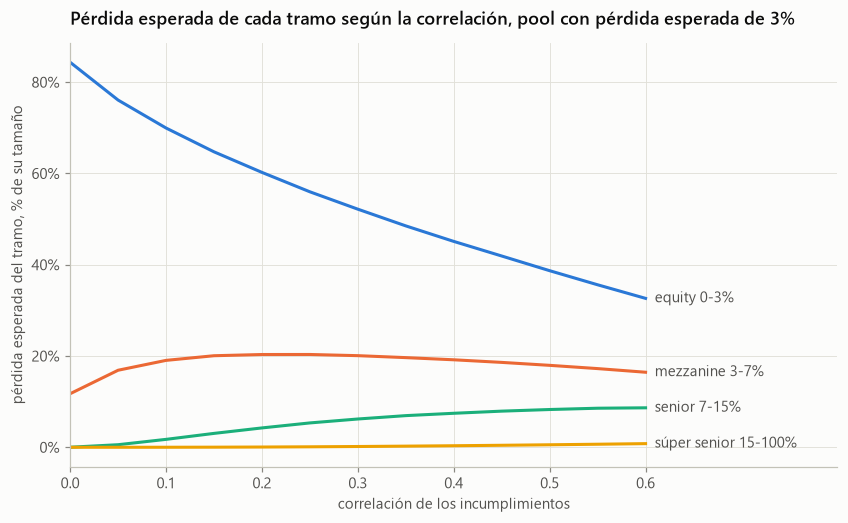

,equity 0-3%,mezzanine 3-7%,senior 7-15%,súper senior 15-100%
correlación,,,,
0.0000,84.36%,11.73%,0.01%,0.00%
0.1000,69.96%,19.04%,1.73%,0.00%
0.3000,52.17%,20.07%,6.20%,0.17%
0.6000,32.63%,16.44%,8.65%,0.80%


In [11]:
tramos = {"equity 0-3%": (0.00, 0.03), "mezzanine 3-7%": (0.03, 0.07), "senior 7-15%": (0.07, 0.15),
          "súper senior 15-100%": (0.15, 1.00)}
rhos = np.round(np.arange(0.0, 0.61, 0.05), 2)
perdida_por_tramo = {t: [] for t in tramos}
for rho in rhos:
    l = fa.perdidas_copula_gaussiana(0.05, max(rho, 1e-6), 125, simulaciones=100_000, lgd=0.60, semilla=2)
    for tramo, (inicio, fin) in tramos.items():
        perdida_por_tramo[tramo].append(fa.perdida_tramo(l, inicio, fin).mean())
tabla_tramos = pd.DataFrame(perdida_por_tramo, index=pd.Index(rhos, name="correlación"))

fig, ax = plt.subplots(figsize=(9, 5))
for color, tramo in zip(COLORES, tramos):
    ax.plot(rhos, tabla_tramos[tramo], color=color, linewidth=2)
    ax.annotate(tramo, (rhos[-1], tabla_tramos[tramo].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=TINTA_SECUNDARIA)
eje_porcentaje(ax)
ax.set_xlim(0, 0.8)
ax.set_xticks(np.arange(0, 0.61, 0.1))
ax.set_xlabel("correlación de los incumplimientos")
ax.set_ylabel("pérdida esperada del tramo, % de su tamaño")
ax.set_title("Pérdida esperada de cada tramo según la correlación, pool con pérdida esperada de 3%")
fig.savefig(FIGURAS / "tramos_cdo.png", bbox_inches="tight")
plt.show()
tabla_tramos.iloc[[0, 2, 6, 12]].map("{:.2%}".format)

**Lectura.**

- **La pérdida esperada del pool es siempre 3%, pero se reparte distinto entre los tramos.** Con correlación cero, el equity pierde en promedio 84% y el senior casi nada. Con correlación de 0,6, el equity pierde 33% y el senior 8,7%.
- **El equity está largo en correlación.** Con alta correlación aumenta la probabilidad de que casi no haya incumplimientos, y eso lo favorece. El senior está corto en correlación: pierde cuando los incumplimientos llegan juntos.
- **El mezzanine no es monótono:** su pérdida sube hasta 20% con correlaciones cercanas a 0,25 y luego baja.
- **La lección de 2007.** Se calibraron correlaciones bajas con datos de años tranquilos. Cuando la correlación real resultó alta, los tramos senior con calificación AAA perdieron valor aunque la pérdida esperada del pool no hubiera cambiado tanto.

### Ejercicios resueltos

**Ejercicio 4.1. Triángulo del crédito** *(ejercicio propio)*

Un CDS a cinco años cotiza 180 puntos base y el mercado supone una recuperación de 40%. ¿Qué intensidad de incumplimiento implica? ¿Cuál es la probabilidad de incumplimiento acumulada a cinco años?

In [12]:
spread, recuperacion = 0.0180, 0.40
lam = fa.intensidad_desde_spread(spread, recuperacion)
supervivencia = np.exp(-lam * 5)
print(f"λ = s / (1 - R) = {spread:.2%} / {1 - recuperacion:.0%} = {lam:.2%} anual")
print(f"Respuesta: supervivencia a 5 años = e^(-{lam:.2f}·5) = {supervivencia:.2%}; PD acumulada = {1 - supervivencia:.2%}")

λ = s / (1 - R) = 1.80% / 60% = 3.00% anual
Respuesta: supervivencia a 5 años = e^(-0.03·5) = 86.07%; PD acumulada = 13.93%


**Ejercicio 4.2. Liquidación de un CDS** *(ejercicio propio)*

Un banco compró protección por USD 50 millones a cinco años con una prima de 200 puntos base anuales. El emisor incumple al final del año 3 y el bono se subasta a 35% de su valor nominal. ¿Cuánto pagó el banco en primas y cuánto recibe? ¿Qué riesgo queda si el vendedor de protección está correlacionado con el emisor?

In [13]:
nominal_cds, prima_anual, recuperacion_subasta = 50.0, 0.02, 0.35
primas = nominal_cds * prima_anual * 3
pago = nominal_cds * (1 - recuperacion_subasta)
print(f"Primas pagadas en tres años: {primas:.1f} millones. Pago de la protección: 50 × (1 - 0,35) = {pago:.1f} millones")
print("Respuesta: el banco recibe 32,5 millones que compensan la pérdida del bono. Si el vendedor de protección"
      " puede quebrar junto con el emisor, queda riesgo de contraparte con correlación adversa (wrong-way risk).")

Primas pagadas en tres años: 3.0 millones. Pago de la protección: 50 × (1 - 0,35) = 32.5 millones
Respuesta: el banco recibe 32,5 millones que compensan la pérdida del bono. Si el vendedor de protección puede quebrar junto con el emisor, queda riesgo de contraparte con correlación adversa (wrong-way risk).


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

En una CDO (Collateralized Debt Obligation) típica, los tramos se estructuran en orden de prioridad de pagos. ¿Cómo afecta el mecanismo de subordinación al perfil de riesgo-retorno de los distintos tramos, y qué evento desencadenó la crisis de las CDOs en 2007-2008?

- **A.** Todos los tramos de una CDO tienen el mismo perfil de riesgo porque comparten el mismo portafolio subyacente de activos.
- **B.** La crisis de las CDOs fue causada principalmente por fraude en la valoración de los activos subyacentes, no por errores en los modelos de correlación.
- **C.** El tramo equity absorbe las primeras pérdidas y ofrece mayor retorno; el tramo senior es el último en perder pero tiene menor rendimiento. La crisis se desencadenó porque las correlaciones de incumplimiento entre hipotecas subprime fueron mucho más altas de lo que los modelos (basados en distribuciones gaussianas) asumían, destruyendo tramos que se creían seguros.
- **D.** El tramo senior absorbe las primeras pérdidas porque tiene mayor tamaño; el tramo equity es el más seguro porque es el último en verse afectado.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** **Estructura de una CDO:** El portafolio de activos genera flujos que se distribuyen por orden de prioridad: Tramo **Senior** (AAA) → Tramo **Mezzanine** (BBB) → Tramo **Equity** (sin calificación). Las pérdidas se absorben en orden inverso: primero el equity, luego el mezzanine, finalmente el senior. Por esto: el equity tiene más riesgo y mayor retorno; el senior tiene menor riesgo y menor rendimiento. **Crisis 2007-2008:** Los modelos (incluyendo la Gaussian Copula de David Li) asumían correlaciones de default relativamente bajas entre hipotecas subprime. Cuando el mercado inmobiliario colapsó, las correlaciones saltaron a cerca de 1 — todas las hipotecas incumplieron juntas. Esto significó que las pérdidas superaron rápidamente al tramo equity y atacaron al mezzanine e incluso al senior, que tenían calificación AAA. La opción D invierte la estructura. La opción A es incorrecta — la subordinación crea perfiles de riesgo muy diferentes. La opción B subestima el rol de los modelos defectuosos.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un banco tiene $50M en bonos corporativos de la empresa XYZ (rating BB). Para cubrir el riesgo de crédito, el banco compra protección mediante un CDS a 5 años con spread de 200 bps (prima anual = 2% del nocional). Si XYZ incumple al final del año 3, ¿cuál es la mecánica del pago y qué representa el spread de 200 bps?

- **A.** El banco recibe $50M completos al incumplimiento sin necesidad de entregar los bonos; el spread de 200 bps es una tarifa administrativa.
- **B.** El banco (comprador de protección) paga 200 bps × $50M = $1M/año durante 3 años. Al incumplimiento, recibe del vendedor de protección: $50M × (1 - Recovery Rate). El spread de 200 bps compensa al vendedor por asumir el riesgo de crédito de XYZ y equivale al precio implícito de mercado del riesgo de default de XYZ.
- **C.** El banco (comprador de protección) recibe el valor nominal ($50M) y entrega los bonos al vendedor de protección; el spread de 200 bps es la prima de riesgo sistémico del mercado crediticio.
- **D.** El spread de 200 bps implica una probabilidad de default del 2% anual bajo cualquier modelo de riesgo de crédito.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** **Mecánica del CDS:**

**Durante la vida del contrato (años 1-3, antes del default):**
- Comprador de protección (banco): paga el spread = 2% × $50M = **$1M/año**
- Vendedor de protección: recibe el spread, no hace ningún pago

**Al evento de crédito (default de XYZ en año 3):**

Liquidación física (traditional):
- Banco entrega los bonos defaulteados → Recibe $50M (nocional completo)

Liquidación en efectivo (cash settlement):
- Banco recibe: $50M × (1 - Recovery Rate)
- Si Recovery Rate = 40%: banco recibe $50M × 0.60 = **$30M**

**Interpretación del spread de 200 bps:**
El spread de un CDS es el precio de mercado del riesgo de crédito de la entidad de referencia. Bajo el modelo de Jarrow-Turnbull simplificado:
$$\text{CDS spread} \approx PD \times (1 - \text{Recovery Rate})$$

Con Recovery Rate = 40%: PD ≈ 200 bps / 0.60 ≈ 3.33% anual

**Por qué los distractores son incorrectos:**
- **A**: Describe correctamente la mecánica pero malinterpreta el spread.
- **C**: En liquidación física el banco SÍ entrega los bonos.
- **D**: El spread no es directamente la PD; depende también de la tasa de recuperación.

</details>

### Trampas frecuentes

- El tramo equity es largo en correlación: gana valor cuando la correlación sube. El senior, al revés.
- La securitización no elimina el riesgo de crédito: lo redistribuye entre los tramos.
- En un CDS, el comprador de protección está corto en el crédito del emisor, aunque no tenga el bono.
- La prima del CDS se paga sobre el nocional, no sobre el valor de mercado del bono.

## FRM-5. Teoría moderna de carteras y CAPM

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Media y varianza.** Con dos activos, $\sigma_p^2 = w_1^2\sigma_1^2 + w_2^2\sigma_2^2 + 2w_1w_2\rho\sigma_1\sigma_2$. La cartera de mínima varianza pone $w_1 = (\sigma_2^2 - \rho\sigma_1\sigma_2)/(\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2)$.
- **Separación en dos fondos.** Con un activo libre de riesgo, todos los inversionistas combinan la misma cartera tangente con el activo libre de riesgo. Con venta corta, la tangente es $w \propto \Sigma^{-1}(\mu - r_f)$.
- **CML y SML.** La línea del mercado de capitales relaciona retorno y volatilidad total, y vale solo para carteras eficientes. La línea del mercado de valores relaciona retorno y beta, y vale para cualquier activo.
- **CAPM.** $E[R_i] = r_f + \beta_i(E[R_m] - r_f)$ con $\beta_i = \text{Cov}(R_i, R_m)/\text{Var}(R_m)$. La beta de una cartera es el promedio ponderado de las betas.
- **Medidas de desempeño.** Sharpe usa el riesgo total; Treynor, la beta; el alfa de Jensen mide el retorno sobre el CAPM; el índice de información divide el retorno activo por el error de seguimiento; M² lleva la cartera a la volatilidad del mercado: $M^2 = r_f + (R_p - r_f)\,\sigma_m/\sigma_p$.

El problema práctico: **las medias se estiman con mucho error**, y la optimización lo amplifica. La cartera "óptima" con datos históricos suele concentrarse en los activos que tuvieron suerte.

### Análisis avanzado: la cartera óptima con error de estimación

Se calcula la cartera de máximo Sharpe con las nueve acciones del IPSA, con y sin venta corta. Luego se remuestrean los retornos 200 veces con reemplazo y se reoptimiza en cada muestra, sin venta corta, como propone Michaud: la dispersión de los pesos muestra cuánto dependen de la muestra.

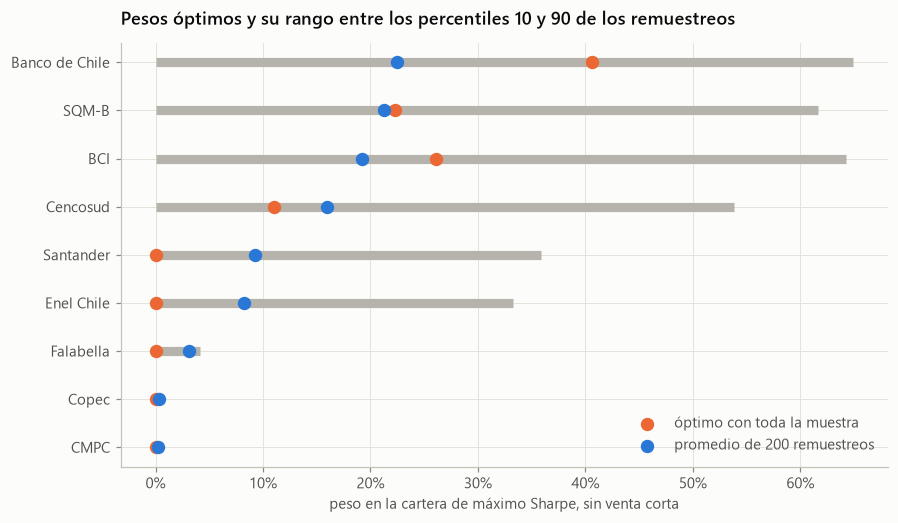

,con venta corta,solo largos,"remuestreo, promedio","remuestreo, p10","remuestreo, p90",muestras con peso > 0
BCI,82.6%,26.1%,19.2%,0.0%,64.2%,47.0%
Santander,-8.7%,0.0%,9.3%,0.0%,35.8%,25.5%
Banco de Chile,95.6%,40.6%,22.5%,0.0%,64.9%,54.0%
Cencosud,53.0%,11.0%,16.0%,0.0%,53.9%,43.5%
CMPC,-97.5%,0.0%,0.2%,0.0%,0.0%,1.0%
Copec,-68.5%,0.0%,0.3%,0.0%,0.0%,3.0%
Enel Chile,19.6%,0.0%,8.2%,0.0%,33.3%,26.5%
Falabella,-23.5%,0.0%,3.1%,0.0%,4.1%,11.0%
SQM-B,47.4%,22.3%,21.2%,0.0%,61.6%,58.5%


In [14]:
r_acc = retornos[acciones]
mu, cov = r_acc.mean() * 252, r_acc.cov() * 252
pesos_libres = pd.Series(fa.pesos_tangencia(mu, cov, rf_anual), index=acciones)
pesos_largos = pd.Series(pf.maximo_sharpe(mu.to_numpy(), cov.to_numpy(), rf_anual), index=acciones)

rng = np.random.default_rng(7)
remuestreos = []
for _ in range(200):
    muestra = r_acc.iloc[rng.integers(0, len(r_acc), len(r_acc))]
    remuestreos.append(pf.maximo_sharpe((muestra.mean() * 252).to_numpy(), (muestra.cov() * 252).to_numpy(), rf_anual))
remuestreos = pd.DataFrame(remuestreos, columns=acciones)

tabla_pesos = pd.DataFrame({"con venta corta": pesos_libres, "solo largos": pesos_largos,
                            "remuestreo, promedio": remuestreos.mean(), "remuestreo, p10": remuestreos.quantile(0.10),
                            "remuestreo, p90": remuestreos.quantile(0.90),
                            "muestras con peso > 0": (remuestreos > 0.01).mean()})

orden = tabla_pesos["remuestreo, promedio"].sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(orden))
ax.hlines(y, tabla_pesos.loc[orden, "remuestreo, p10"], tabla_pesos.loc[orden, "remuestreo, p90"], color=NEUTRO, linewidth=6)
ax.scatter(tabla_pesos.loc[orden, "solo largos"], y, color=COLORES[1], s=60, zorder=3, label="óptimo con toda la muestra")
ax.scatter(tabla_pesos.loc[orden, "remuestreo, promedio"], y, color=COLORES[0], s=60, zorder=3, label="promedio de 200 remuestreos")
ax.set_yticks(y, orden)
eje_porcentaje(ax, "x")
ax.set_xlabel("peso en la cartera de máximo Sharpe, sin venta corta")
ax.set_title("Pesos óptimos y su rango entre los percentiles 10 y 90 de los remuestreos")
ax.legend(loc="lower right")
fig.savefig(FIGURAS / "pesos_remuestreo.png", bbox_inches="tight")
plt.show()
tabla_pesos.map("{:.1%}".format)

¿Qué cartera funciona mejor fuera de la muestra? Se estiman los pesos con 2019 a 2022 y se evalúan de 2023 en adelante.

In [15]:
entrenamiento, prueba = r_acc.loc[:"2022"], r_acc.loc["2023":]
mu_e, cov_e = entrenamiento.mean() * 252, entrenamiento.cov() * 252
rng = np.random.default_rng(11)
promedio_remuestreo = np.mean([
    pf.maximo_sharpe((m.mean() * 252).to_numpy(), (m.cov() * 252).to_numpy(), rf_anual)
    for m in (entrenamiento.iloc[rng.integers(0, len(entrenamiento), len(entrenamiento))] for _ in range(200))
], axis=0)
estrategias = {
    "máximo Sharpe histórico": pf.maximo_sharpe(mu_e.to_numpy(), cov_e.to_numpy(), rf_anual),
    "máximo Sharpe remuestreado": promedio_remuestreo,
    "mínima varianza": pf.minima_varianza(cov_e.to_numpy()),
    "pesos iguales": np.full(len(acciones), 1 / len(acciones)),
}
rf_prueba = float(tpm.loc["2023":].mean())
fuera = {}
for nombre, w in estrategias.items():
    r_p = prueba @ w
    fuera[nombre] = {"retorno anual": r_p.mean() * 252, "volatilidad anual": r_p.std() * np.sqrt(252),
                     "Sharpe": (r_p.mean() * 252 - rf_prueba) / (r_p.std() * np.sqrt(252)),
                     "peso máximo": np.max(w)}
pd.DataFrame(fuera).T

,retorno anual,volatilidad anual,Sharpe,peso máximo
máximo Sharpe histórico,0.0891,0.3732,0.0602,0.8551
máximo Sharpe remuestreado,0.1299,0.2679,0.2362,0.5432
mínima varianza,0.2652,0.1647,1.2060,0.2920
pesos iguales,0.2134,0.1643,0.8931,0.1111


**Lectura.**

- **Con venta corta, la cartera óptima toma posiciones extremas:** 96% en Banco de Chile y −98% en CMPC. Sin venta corta se concentra en cuatro acciones: Banco de Chile 41%, BCI 26%, SQM-B 22% y Cencosud 11%.
- **Esa concentración es frágil.** Entre los percentiles 10 y 90 de los remuestreos, el peso de Banco de Chile va de 0% a 65%, y la acción queda con peso relevante en solo 54% de las muestras. El promedio de los remuestreos reparte mejor.
- **Fuera de la muestra gana lo que no depende de medias estimadas.** Entre 2023 y 2026, la cartera de máximo Sharpe histórico, con 86% en una acción, tuvo un Sharpe de 0,06. La remuestreada llegó a 0,24, la de pesos iguales a 0,89 y la de mínima varianza a 1,21. Es el resultado de DeMiguel, Garlappi y Uppal (2009): la cartera 1/N es difícil de superar.

### Ejercicios resueltos

**Ejercicio 5.1. Cartera de dos activos** *(banco de ejercicios de frm-prep)*

Una cartera invierte 60% en A (σ = 20%) y 40% en B (σ = 10%), con correlación 0,3. Calcula su desviación estándar. Luego, para dos activos no correlacionados con volatilidades de 12% y 18%, calcula el peso en el primero que minimiza la varianza.

In [16]:
w = np.array([0.6, 0.4])
vols = np.array([0.20, 0.10])
cov_ab = np.outer(vols, vols) * np.array([[1, 0.3], [0.3, 1]])
print(f"σ_p = raíz(w' Σ w) = {np.sqrt(w @ cov_ab @ w):.2%}")
minima = fa.pesos_minima_varianza(np.diag([0.12**2, 0.18**2]))
print(f"Peso de mínima varianza en el activo de 12%: 0,18² / (0,12² + 0,18²) = {minima[0]:.1%}")
print("Respuesta: σ ≈ 13,74% y w ≈ 69,2%.")

σ_p = raíz(w' Σ w) = 13.74%
Peso de mínima varianza en el activo de 12%: 0,18² / (0,12² + 0,18²) = 69.2%
Respuesta: σ ≈ 13,74% y w ≈ 69,2%.


**Ejercicio 5.2. CAPM y beta de una cartera** *(banco de ejercicios de frm-prep)*

Una acción tiene beta 1,2, la tasa libre de riesgo es 2,5% y el mercado espera 9%: ¿qué retorno exige el CAPM? Una cartera invierte 70% en una acción con beta 1,3 y 30% en otra con beta 0,6: ¿cuál es su beta? Y si A espera 10% y B 6%, con pesos de 60% y 40%, ¿cuál es el retorno esperado?

In [17]:
print(f"Retorno exigido: 2,5% + 1,2 × (9% - 2,5%) = {0.025 + 1.2 * (0.09 - 0.025):.1%}")
print(f"Beta de la cartera: 0,7 × 1,3 + 0,3 × 0,6 = {0.7 * 1.3 + 0.3 * 0.6:.2f}")
print(f"Retorno esperado: 0,6 × 10% + 0,4 × 6% = {0.6 * 0.10 + 0.4 * 0.06:.1%}")

Retorno exigido: 2,5% + 1,2 × (9% - 2,5%) = 10.3%
Beta de la cartera: 0,7 × 1,3 + 0,3 × 0,6 = 1.09
Retorno esperado: 0,6 × 10% + 0,4 × 6% = 8.4%


**Ejercicio 5.3. Cartera tangente y línea del mercado de capitales** *(ejercicio propio)*

Tres activos esperan 8%, 12% y 10%, con volatilidades de 15%, 25% y 20% y correlaciones de 0,3 entre el primero y el segundo, 0,2 entre el primero y el tercero y 0,4 entre el segundo y el tercero. La tasa libre de riesgo es 3%. Encuentra la cartera tangente con venta corta, su Sharpe, y cómo debe invertir un inversionista que quiere una volatilidad de 10%.

In [18]:
mu3 = np.array([0.08, 0.12, 0.10])
vol3 = np.array([0.15, 0.25, 0.20])
cov3 = np.outer(vol3, vol3) * np.array([[1, 0.3, 0.2], [0.3, 1, 0.4], [0.2, 0.4, 1]])
w_t = fa.pesos_tangencia(mu3, cov3, 0.03)
ret_t, vol_t = w_t @ mu3, np.sqrt(w_t @ cov3 @ w_t)
sharpe_t = (ret_t - 0.03) / vol_t
y = 0.10 / vol_t
print("Pesos de la cartera tangente:", np.round(w_t, 3))
print(f"Retorno {ret_t:.2%}, volatilidad {vol_t:.2%}, Sharpe {sharpe_t:.3f}")
print(f"Respuesta: para σ = 10% invierte {y:.1%} en la tangente y {1 - y:.1%} en el activo libre de riesgo;"
      f" su retorno esperado es 3% + {sharpe_t:.3f} × 10% = {0.03 + sharpe_t * 0.10:.2%}.")

Pesos de la cartera tangente: [0.441 0.235 0.324]
Retorno 9.59%, volatilidad 13.83%, Sharpe 0.476
Respuesta: para σ = 10% invierte 72.3% en la tangente y 27.7% en el activo libre de riesgo; su retorno esperado es 3% + 0.476 × 10% = 7.76%.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Una cartera tiene un ratio de Sharpe de 0.8; el del mercado es 0.6 y la volatilidad del mercado es 10%. La medida M-cuadrado (M2) — el exceso ajustado por riesgo de la cartera sobre el mercado — es más cercana a:

- **A.** 2.0%
- **B.** 0.2%
- **C.** 8.0%
- **D.** 0.8%

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** $M^2 = (\text{Sharpe}_p - \text{Sharpe}_m)\,\sigma_m = (0.8 - 0.6)\times 10\% = 2.0\%$: el retorno extra sobre el mercado al nivel de riesgo del mercado.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un inversor mantiene una cartera bien diversificada que representa toda su riqueza. Un gestor alega superioridad a través de un alto ratio de Treynor. ¿Cuál es la crítica más apropiada?

- **A.** Para un inversor bien diversificado, importa el riesgo total, por lo que el ratio de Sharpe es más apropiado que el ratio de Treynor, que solo captura el riesgo sistemático
- **B.** El ratio de información es mejor porque el inversor tiene un índice de referencia específico
- **C.** El ratio de Treynor sobreestima el rendimiento cuando el alfa es positivo
- **D.** El ratio de Treynor no ajusta por la tasa libre de riesgo

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** El Treynor usa la beta (riesgo sistemático), apropiado cuando la cartera es un componente de una cartera diversificada más grande. Cuando la cartera representa toda la riqueza del inversor, importa la volatilidad total, haciendo que el Sharpe sea la medida correcta.

</details>

### Trampas frecuentes

- La CML usa σ y solo sirve para carteras eficientes; la SML usa β y sirve para cualquier activo.
- Treynor es para una cartera que es parte de otra diversificada; Sharpe, para la cartera que es toda la riqueza.
- Un alfa de Jensen positivo no prueba habilidad: con pocos años de datos el error estándar es enorme.
- La beta de una cartera es el promedio ponderado de las betas, pero su volatilidad no es el promedio de las volatilidades.

## FRM-6. La teoría de precios por arbitraje y los modelos multifactoriales

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Modelo de factores.** $R_i = E[R_i] + \sum_k \beta_{ik} F_k + \varepsilon_i$, con factores de media cero y riesgo idiosincrático $\varepsilon_i$ no correlacionado entre activos.
- **APT de Ross.** Si no hay arbitraje, el retorno esperado es lineal en las cargas: $E[R_i] = r_f + \sum_k \beta_{ik}\lambda_k$, con $\lambda_k$ la prima del factor k. No necesita identificar la cartera de mercado ni supuestos sobre preferencias, pero tampoco dice cuáles son los factores.
- **Cartera de arbitraje.** Con más activos que factores, se puede armar una cartera de costo cero y sin exposición a los factores. Si su retorno esperado no es cero, hay arbitraje.
- **Covarianzas.** El modelo reduce los parámetros: $\Sigma = B\,\Sigma_F\,B' + D$, con D diagonal. La varianza de cada activo se separa en una parte sistemática y otra idiosincrática.
- **Fama-French.** Mercado, tamaño (SMB) y valor (HML), a los que luego se agregaron rentabilidad, inversión y momentum.

### Análisis avanzado: riesgo sistemático e idiosincrático de las acciones del IPSA

Se estima un modelo de tres factores con retornos semanales desde 2019: el ETF IPSA como factor de mercado, el dólar y el precio del cobre. Se usan datos semanales porque el cobre y el dólar se publican con rezago y los retornos diarios mezclarían días distintos.

400 semanas. Error absoluto medio de las correlaciones implícitas en el modelo: 0.058


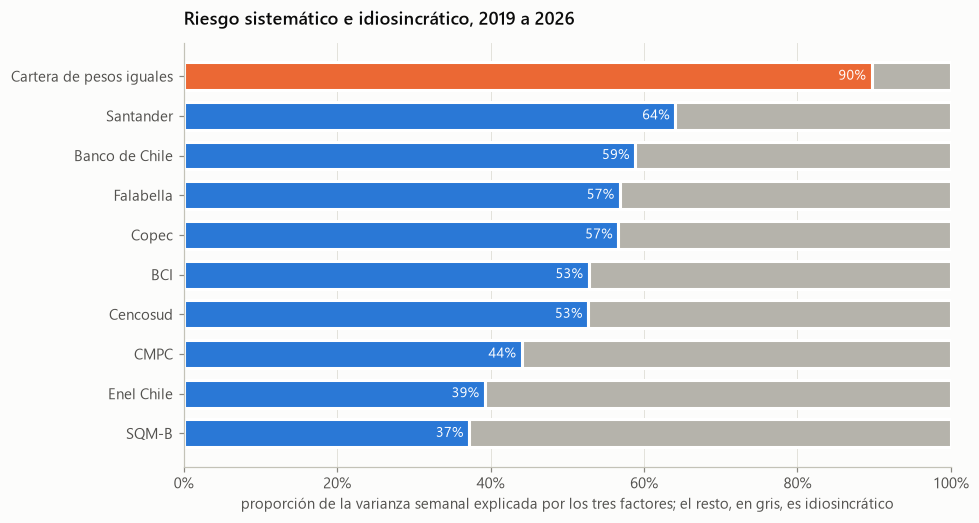

,ETF IPSA,Dólar,Cobre,R2
BCI,0.8970,-0.0700,-0.0940,0.5280
Santander,1.0050,0.1440,-0.0620,0.6410
Banco de Chile,0.8750,0.0260,-0.0860,0.5880
Cencosud,1.1100,0.2150,0.1000,0.5270
CMPC,0.9630,0.1020,0.0440,0.4400
Copec,0.9630,-0.0610,0.0790,0.5670
Enel Chile,0.8420,-0.1170,0.0710,0.3920
Falabella,1.2030,-0.0140,-0.0160,0.5690
SQM-B,1.1140,-0.0070,0.1360,0.3720


In [19]:
niveles = pd.concat([precios, dolar_alineado.rename("Dólar"), cobre_alineado.rename("Cobre")], axis=1, sort=True).ffill()
semanal = np.log(niveles.loc[precios.index[0]:precios.index[-1]]).resample("W-WED").last().diff().dropna()
factores = semanal[["ETF IPSA", "Dólar", "Cobre"]]
x_factores = sm.add_constant(factores)

cargas, varianza_residual, r2 = {}, {}, {}
for accion in acciones:
    modelo = sm.OLS(semanal[accion], x_factores).fit()
    cargas[accion] = modelo.params.drop("const")
    varianza_residual[accion] = modelo.resid.var()
    r2[accion] = modelo.rsquared
cargas = pd.DataFrame(cargas).T
cov_factores = factores.cov()
sistematica = pd.Series(np.einsum("ij,jk,ik->i", cargas, cov_factores, cargas), index=acciones)
total = semanal[acciones].var()

# Cartera de pesos iguales: el riesgo idiosincrático se diversifica.
w_iguales = np.full(len(acciones), 1 / len(acciones))
b_cartera = w_iguales @ cargas
sist_cartera = float(b_cartera @ cov_factores @ b_cartera)
idio_cartera = float(np.sum(w_iguales**2 * pd.Series(varianza_residual)))
proporcion = (sistematica / total).sort_values()
proporcion["Cartera de pesos iguales"] = sist_cartera / (sist_cartera + idio_cartera)

cov_modelo = cargas @ cov_factores @ cargas.T + np.diag(pd.Series(varianza_residual))
desv = np.sqrt(np.diag(cov_modelo))
corr_modelo = cov_modelo / np.outer(desv, desv)
corr_muestral = semanal[acciones].corr()
fuera_diagonal = ~np.eye(len(acciones), dtype=bool)
error_corr = np.abs(corr_modelo.to_numpy() - corr_muestral.to_numpy())[fuera_diagonal].mean()
print(f"{len(semanal)} semanas. Error absoluto medio de las correlaciones implícitas en el modelo: {error_corr:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(proporcion))
ax.barh(y, proporcion, color=[COLORES[1] if n == "Cartera de pesos iguales" else COLORES[0] for n in proporcion.index],
        edgecolor="white", linewidth=2, height=0.7)
ax.barh(y, 1 - proporcion, left=proporcion, color=NEUTRO, edgecolor="white", linewidth=2, height=0.7)
for yi, valor in zip(y, proporcion):
    ax.annotate(f"{valor:.0%}", (valor, yi), xytext=(-4, 0), textcoords="offset points", ha="right", va="center",
                color="white", fontsize=9)
ax.set_yticks(y, proporcion.index)
eje_porcentaje(ax, "x")
ax.set_xlim(0, 1)
ax.set_xlabel("proporción de la varianza semanal explicada por los tres factores; el resto, en gris, es idiosincrático")
ax.set_title("Riesgo sistemático e idiosincrático, 2019 a 2026")
plt.show()
cargas.assign(R2=pd.Series(r2)).round(3)

**Lectura.**

- **El mercado domina.** Las cargas al ETF IPSA van de 0,84 en Enel a 1,20 en Falabella. Las del dólar y el cobre son pequeñas, porque su efecto ya se refleja en buena parte en el índice.
- **Entre 37% y 64% de la varianza de cada acción es sistemática;** el resto es idiosincrático. SQM-B y Enel Chile son las más propias, con R² cercanos a 0,4.
- **En la cartera de pesos iguales, la parte sistemática sube a 90%.** Diversificar elimina casi todo el riesgo propio de cada empresa, pero no el de mercado, que es el único que el CAPM y la APT premian.
- **El modelo reproduce bien las correlaciones,** con un error absoluto medio de 0,06, usando 3 factores y 9 varianzas residuales en vez de estimar las 36 correlaciones una por una.

### Ejercicios resueltos

**Ejercicio 6.1. Retorno esperado con la APT** *(ejercicio propio)*

La tasa libre de riesgo es 4%. Una acción tiene cargas de 1,2 al mercado, −0,4 a la inflación y 0,5 al cobre, y las primas de esos factores son 6%, −1% y 2%. ¿Cuál es su retorno esperado según la APT?

In [20]:
cargas_ej, primas_ej = np.array([1.2, -0.4, 0.5]), np.array([0.06, -0.01, 0.02])
esperado = fa.retorno_apt(0.04, cargas_ej, primas_ej)
print(f"E[R] = 4% + 1,2·6% + (-0,4)·(-1%) + 0,5·2% = {esperado:.1%}")
print("Respuesta: 12,6%. La carga negativa a la inflación, con prima negativa, suma retorno: la acción protege contra la inflación y aun así rinde más.")

E[R] = 4% + 1,2·6% + (-0,4)·(-1%) + 0,5·2% = 12.6%
Respuesta: 12,6%. La carga negativa a la inflación, con prima negativa, suma retorno: la acción protege contra la inflación y aun así rinde más.


**Ejercicio 6.2. Construir un arbitraje** *(ejercicio propio)*

Tres carteras bien diversificadas dependen de un solo factor, con cargas de 1,0, 1,5 y 2,0 y retornos esperados de 8%, 10% y 14%. ¿Hay arbitraje? Si lo hay, arma la cartera de costo cero y sin exposición al factor.

In [21]:
cargas_arb = np.array([[1.0], [1.5], [2.0]])
esperados = np.array([0.08, 0.10, 0.14])
w_arb = fa.cartera_arbitraje(cargas_arb, esperados)
print("Pesos:", np.round(w_arb, 3), f"| suma: {w_arb.sum():.3f} | exposición al factor: {w_arb @ cargas_arb[:, 0]:.3f}")
print(f"Respuesta: comprar 0,5 de la primera y 0,5 de la tercera, y vender 1 de la segunda, rinde {w_arb @ esperados:.1%} sin riesgo ni inversión."
      " La segunda está cara: su retorno queda bajo la recta que une a las otras dos.")

Pesos: [ 0.5 -1.   0.5] | suma: 0.000 | exposición al factor: 0.000
Respuesta: comprar 0,5 de la primera y 0,5 de la tercera, y vender 1 de la segunda, rinde 1.0% sin riesgo ni inversión. La segunda está cara: su retorno queda bajo la recta que une a las otras dos.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

Comparado con el CAPM de un solo factor, un modelo multifactorial (p. ej., APT o Fama-French) explica los retornos de los activos usando:

- **A.** varios factores de riesgo sistemático (p. ej., mercado, tamaño, valor, momentum), cada uno con su propia prima de riesgo.
- **B.** solo la tasa libre de riesgo.
- **C.** un único factor de mercado y nada más.
- **D.** solo el riesgo idiosincrático.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** El CAPM usa un factor (el mercado). El APT y los modelos multifactoriales empíricos agregan factores como tamaño, valor, momentum o variables macro, cada uno con una prima. Suelen explicar la sección cruzada de retornos mejor que el CAPM de un factor.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

La Teoría de Valoración por Arbitraje (APT) de Ross es una alternativa al CAPM. ¿Cuál de las siguientes afirmaciones describe mejor las diferencias y limitaciones clave entre el APT y el CAPM?

- **A.** El APT y el CAPM producen el mismo precio de equilibrio para todos los activos cuando el mercado es eficiente, por lo que la elección entre ellos es solo una cuestión de conveniencia computacional.
- **B.** El APT asume que todos los inversores tienen el mismo horizonte temporal y expectativas homogéneas, igual que el CAPM, pero usa múltiples factores en lugar de uno.
- **C.** El APT no especifica cuáles son los factores — los determina empíricamente — y su supuesto fundamental es que no pueden existir oportunidades de arbitraje; a diferencia del CAPM, no requiere identificar la cartera de mercado, pero es menos operativo porque los factores no están predefinidos.
- **D.** El APT garantiza una valoración más precisa que el CAPM porque usa más factores y los factores adicionales siempre capturan más riesgo relevante.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** **APT (Ross, 1976):** El retorno de un activo = α + β₁F₁ + β₂F₂ + ... + βₙFₙ + ε, donde los F son factores macroeconómicos o estadísticos. Supuesto central: **no hay arbitraje** — si dos carteras tienen las mismas exposiciones a los factores, deben tener el mismo retorno esperado. **Ventajas sobre CAPM:** No requiere identificar la cartera de mercado (el mayor problema empírico del CAPM — Roll's critique). Permite múltiples fuentes de riesgo sistemático. **Limitaciones del APT:** No especifica cuántos factores existen ni cuáles son — hay que identificarlos empíricamente (modelos de factores como Fama-French 3F, 5F). La eliminación de arbitraje es aproximada, no exacta, en carteras finitas. **Limitaciones del CAPM:** Depende de identificar la 'cartera de mercado' verdadera (Roll's critique: inobservable). Asume un solo factor de riesgo. La opción B es incorrecta — el APT no requiere expectativas homogéneas ni el mismo horizonte. La opción D es incorrecta — más factores no garantizan mayor precisión si están mal especificados. La opción A es incorrecta — pueden divergir significativamente.

</details>

### Trampas frecuentes

- La APT no dice cuáles son los factores ni cuántos: eso es empírico.
- El riesgo idiosincrático no tiene premio en la APT, porque se diversifica en carteras grandes.
- Un arbitraje exige costo cero y exposición cero a los factores; si queda exposición, es una apuesta.
- Las cargas son sensibilidades, no pesos: pueden ser negativas y no suman uno.

## FRM-7. Principios para la agregación efectiva de datos de riesgo

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

El documento BCBS 239 (2013) nació porque en la crisis muchos bancos no pudieron sumar a tiempo su exposición a Lehman Brothers entre filiales y sistemas. Tiene 14 principios en cuatro grupos:

| Grupo | Principios |
|---|---|
| Gobierno e infraestructura | Gobierno de los datos aprobado por el directorio; arquitectura e infraestructura de TI que soporte la agregación en tiempos normales y de estrés |
| Capacidad de agregación | Exactitud e integridad, completitud, oportunidad y adaptabilidad |
| Reportes de riesgo | Exactitud, exhaustividad, claridad y utilidad, frecuencia y distribución |
| Revisión supervisora | Revisión, medidas correctivas y cooperación entre supervisores |

Ideas clave:

- **Exactitud y automatización.** Los datos se concilian contra fuentes contables, y los procesos manuales se documentan y controlan.
- **Completitud.** Todas las exposiciones materiales, por línea de negocio, entidad legal, tipo de activo, industria y región.
- **Oportunidad y adaptabilidad.** Poder producir reportes a pedido en una crisis, con agregaciones que nadie anticipó.
- **Taxonomías comunes.** Un mismo cliente con el mismo identificador en todos los sistemas; sin eso, la exposición se subestima.

### Análisis avanzado: control de calidad sobre datos reales de la CMF

Se aplican controles de BCBS 239 a tres archivos de indicadores bancarios descargados de la API de la CMF para este repositorio: patrimonio efectivo sobre activos ponderados por riesgo, cartera deteriorada y rentabilidad sobre patrimonio. Los controles miden completitud, consistencia de identificadores, oportunidad y validez.

In [22]:
def leer_cmf(patron):
    ruta = next((DATOS / "cmf").glob(patron))
    tabla = pd.read_csv(ruta)
    tabla["fecha"] = pd.to_datetime(tabla["fecha"])
    tabla["codigo"] = tabla["codigo_serie"].str.extract(r"AGIFI_([A-Z0-9]+)_STO")[0]
    return tabla

fuentes = {"capital": leer_cmf("*PATEFE_APR*"), "cartera deteriorada": leer_cmf("*CARDETER*"), "ROAE": leer_cmf("*ROAE*")}
corte = max(t["fecha"].max() for t in fuentes.values())

resumen_fuentes = {}
for nombre, t in fuentes.items():
    meses = pd.period_range(t["fecha"].min(), t["fecha"].max(), freq="M")
    presentes = t.groupby("codigo")["fecha"].nunique()
    resumen_fuentes[nombre] = {"desde": f"{t['fecha'].min():%m-%Y}", "hasta": f"{t['fecha'].max():%m-%Y}",
                               "meses de rezago": (corte.to_period("M") - t["fecha"].max().to_period("M")).n,
                               "instituciones": t["codigo"].nunique(), "completitud media": presentes.mean() / len(meses),
                               "duplicados": int(t.duplicated(["codigo", "fecha"]).sum())}
print("Resumen por fuente:")
print(pd.DataFrame(resumen_fuentes).T.to_string())

nombres = pd.concat([t[["codigo", "nombre"]].assign(fuente=f) for f, t in fuentes.items()])
nombres["nombre"] = nombres["nombre"].str.replace("\xa0", " ").str.strip()
variantes = nombres.drop_duplicates(["codigo", "nombre"]).groupby("codigo")["nombre"].apply(list)
inconsistentes = variantes[variantes.str.len() > 1]
print(f"\nCódigos con más de un nombre entre fuentes: {len(inconsistentes)}")
for codigo, lista in inconsistentes.items():
    print(f"  {codigo}: {' | '.join(lista)}")

codigos = {f: set(t["codigo"]) for f, t in fuentes.items()}
todos = set.union(*codigos.values())
faltantes = {c: [f for f in fuentes if c not in codigos[f]] for c in todos}
print("\nInstituciones que faltan en alguna fuente:", {c: f for c, f in faltantes.items() if f})

ultimo = {f: t[t["fecha"] == t["fecha"].max()].set_index("codigo")["valor"] for f, t in fuentes.items()}
alertas = pd.DataFrame({
    "capital sobre 100%": ultimo["capital"] > 100,
    "capital bajo 10,5%": ultimo["capital"] < 10.5,
    "cartera deteriorada igual a 0": ultimo["cartera deteriorada"] == 0,
    "ROAE fuera de ±60%": ultimo["ROAE"].abs() > 60,
}).fillna(False)
alertas = alertas[alertas.any(axis=1)]
alertas.index = [variantes[c][0] for c in alertas.index]
alertas

Resumen por fuente:
                       desde    hasta meses de rezago instituciones completitud media duplicados
capital              12-2021  06-2026               1            18            0.9909          0
cartera deteriorada  08-2019  07-2026               0            19            0.8734          0
ROAE                 08-2019  07-2026               0            18            0.9570          0

Códigos con más de un nombre entre fuentes: 2
  BCI: Banco de Crédito e Inversiones | Banco de Credito e Inversiones
  HSBC: HSBC Bank (Chile) | Hsbc Bank (Chile)

Instituciones que faltan en alguna fuente: {'SISTBANC': ['cartera deteriorada', 'ROAE'], 'TANNERBD': ['capital', 'ROAE'], 'BBRA': ['capital']}


,capital sobre 100%,"capital bajo 10,5%",cartera deteriorada igual a 0,ROAE fuera de ±60%
Bank of China,True,False,True,False
HSBC Bank (Chile),False,False,True,False


**Lectura.** Los controles encuentran problemas reales en datos oficiales:

- **Oportunidad.** El archivo de capital llega a junio de 2026 y los otros dos a julio. Un reporte que los combine sin controlar la fecha de corte mezcla meses distintos.
- **Consistencia de identificadores.** BCI aparece con y sin tilde, y HSBC con distintas mayúsculas, según la fuente. Unir las tablas por nombre habría separado a cada banco en dos; hay que unirlas por el código.
- **Conciliación.** Banco do Brasil falta en la fuente de capital, Tanner falta en capital y ROAE, y el agregado del sistema bancario aparece solo en la de capital. Sumar ese agregado junto con los bancos duplicaría los montos.
- **Validez.** Bank of China reporta un ratio de capital de 288% y cartera deteriorada igual a cero, y HSBC también reporta cero. Pueden ser datos correctos de sucursales pequeñas, pero un buen control los marca para revisión en vez de dejarlos pasar.

### Ejercicios resueltos

**Ejercicio 7.1. Agregar exposiciones entre sistemas** *(ejercicio propio)*

Un banco registra créditos en un sistema y derivados en otro. Cada sistema escribe los nombres de los clientes a su manera. El límite por contraparte es de 1.000 millones. Normaliza los identificadores, agrega la exposición y encuentra los excesos que ninguna vista por sistema muestra. Los datos son ficticios.

In [23]:
creditos = pd.DataFrame({"cliente": ["Minera Andes S.A.", "Retail Sur SpA", "Energía Norte S.A.", "Forestal Austral"],
                         "exposicion": [700.0, 450.0, 300.0, 600.0]})
derivados = pd.DataFrame({"cliente": ["MINERA ANDES SA", "Energia Norte SA", "Forestal Austral S.A.", "Agrícola Centro"],
                          "exposicion": [450.0, 200.0, 350.0, 150.0]})

def normalizar(nombre):
    import unicodedata
    texto = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode().upper()
    texto = texto.replace(".", "").replace(",", "")
    for sufijo in (" SPA", " SA"):
        texto = texto.removesuffix(sufijo)
    return texto.strip()

todas = pd.concat([creditos.assign(sistema="créditos"), derivados.assign(sistema="derivados")])
todas["id"] = todas["cliente"].map(normalizar)
agregada = todas.groupby("id")["exposicion"].sum().sort_values(ascending=False)
print(f"Contrapartes según los nombres originales: {todas['cliente'].nunique()}; reales: {agregada.size}")
print("Exposición agregada:")
print(agregada.to_string())
print(f"Máximo en un solo sistema: {todas['exposicion'].max():,.0f}")
print("Respuesta: ninguna exposición supera el límite dentro de un sistema, pero Minera Andes (1.150) y"
      " Forestal Austral (950, cerca del límite) aparecen al agregar. Es la falla que BCBS 239 busca evitar.")

Contrapartes según los nombres originales: 8; reales: 5
Exposición agregada:
id
MINERA ANDES       1,150.0000
FORESTAL AUSTRAL     950.0000
ENERGIA NORTE        500.0000
RETAIL SUR           450.0000
AGRICOLA CENTRO      150.0000
Máximo en un solo sistema: 700
Respuesta: ninguna exposición supera el límite dentro de un sistema, pero Minera Andes (1.150) y Forestal Austral (950, cerca del límite) aparecen al agregar. Es la falla que BCBS 239 busca evitar.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

El informe de riesgo de un banco muestra el VaR del libro de trading pero no puede producirse a demanda durante un evento de estrés de mercado en fin de semana. Esto viola cuál principio de BCBS 239?

- **A.** Granularidad
- **B.** Completitud
- **C.** Oportunidad y adaptabilidad
- **D.** Precisión

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** BCBS 239 exige que los informes de riesgo puedan producirse de manera oportuna, incluso durante el estrés. La capacidad de generar informes a solicitud de la alta dirección en cualquier momento —no solo en las fechas de reporte programadas— es un requisito específico.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Los principios de BCBS 239 sobre agregación de datos de riesgo requieren principalmente que los bancos:

- **A.** Aseguren que los datos sean precisos, oportunos, completos y adaptables para producir informes de riesgo durante el estrés
- **B.** Eliminen toda redundancia de datos en sus sistemas
- **C.** Reporten datos de riesgo a los reguladores diariamente
- **D.** Terceroricen la gestión de datos a proveedores externos

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Los cuatro principios clave de BCBS 239 para datos de riesgo: precisión e integridad, completitud, oportunidad y adaptabilidad. El objetivo es que la alta dirección pueda acceder a información de riesgo oportuna y precisa, especialmente durante el estrés.

</details>

### Trampas frecuentes

- BCBS 239 no fija requerimientos de capital ni exige un modelo de riesgo: trata de datos, sistemas y reportes.
- Un reporte que no puede generarse a pedido durante una crisis falla en oportunidad y adaptabilidad, aunque sea exacto.
- La exactitud se prueba conciliando contra la contabilidad, no comparando el reporte consigo mismo.
- Los principios aplican primero a los bancos sistémicos (G-SIB), pero los supervisores los extienden a otros.

## FRM-8. Gestión integral de riesgos y tendencias futuras

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

- **ERM frente a silos.** La gestión integral mira todos los riesgos juntos, con sus interacciones, y los conecta con la estrategia y el capital. Evita tanto la doble contabilidad como las concentraciones que ningún silo ve.
- **Capital económico.** Se mide por tipo de riesgo y se agrega con correlaciones o cópulas. La agregación con correlaciones entrega un beneficio de diversificación que se reduce en estrés.
- **Asignación del capital.** La contribución de Euler, $EC_i = m_i\,(C\,m)_i/\sqrt{m'Cm}$, reparte el capital diversificado y suma exactamente el total.
- **RAROC.** $(\text{ingresos} - \text{costos} - EL + \text{retorno del capital})/EC$. Una línea crea valor si su RAROC supera el costo del capital; el EVA es $(\text{RAROC} - \text{costo del capital}) \times EC$.
- **Cultura de riesgo y tendencias.** Riesgo climático (físico y de transición), ciberriesgo, riesgo de modelos e inteligencia artificial, y riesgo de terceros.

### Análisis avanzado: agregación de capital económico y RAROC

Un banco con tres líneas de negocio tiene capital individual por riesgo de crédito, mercado y operacional. Las cifras son ilustrativas. La correlación entre dos componentes es el producto de la correlación entre líneas y la correlación entre tipos de riesgo, una matriz de Kronecker.

Suma simple: 3,280. Capital diversificado: 2,284. Beneficio de diversificación: 30.4%


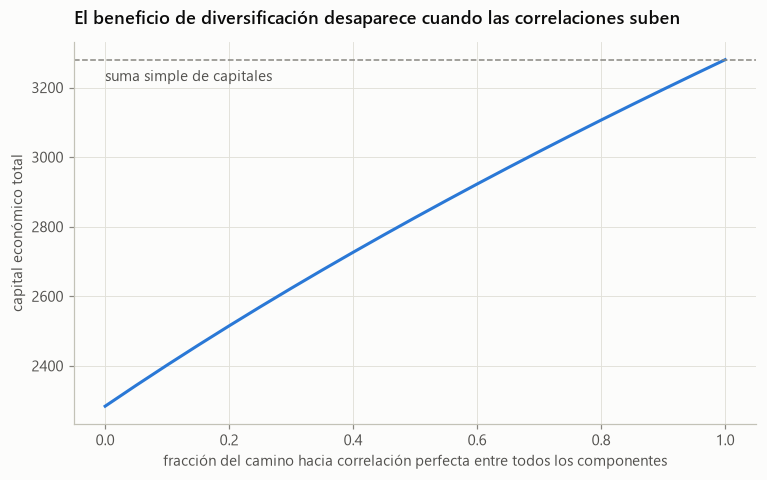

,ingresos,costos,pérdida esperada,capital individual,capital diversificado,RAROC individual,RAROC diversificado,EVA diversificado
Personas,620.0000,300.0000,140.0000,"1,100.0000",791.0420,0.2140,0.2780,124.6270
Empresas,540.0000,180.0000,90.0000,"1,400.0000","1,132.8040",0.2430,0.2880,190.7040
Tesorería,140.0000,90.0000,5.0000,780.0000,360.1430,0.1080,0.1750,19.7900


In [24]:
lineas, riesgos = ["Personas", "Empresas", "Tesorería"], ["Crédito", "Mercado", "Operacional"]
capital_individual = pd.DataFrame([[900, 50, 150], [1_200, 80, 120], [100, 600, 80]], index=lineas, columns=riesgos, dtype=float)
corr_riesgos = np.array([[1.0, 0.5, 0.2], [0.5, 1.0, 0.2], [0.2, 0.2, 1.0]])
corr_lineas = np.array([[1.0, 0.6, 0.3], [0.6, 1.0, 0.4], [0.3, 0.4, 1.0]])
corr_total = np.kron(corr_lineas, corr_riesgos)
montos = capital_individual.to_numpy().ravel()

total_diversificado = fa.agregar_riesgos(montos, corr_total)
euler = montos * (corr_total @ montos) / total_diversificado
capital_por_linea = pd.Series(euler.reshape(3, 3).sum(axis=1), index=lineas)

negocio = pd.DataFrame({"ingresos": [620.0, 540.0, 140.0], "costos": [300.0, 180.0, 90.0], "pérdida esperada": [140.0, 90.0, 5.0]},
                       index=lineas)
costo_capital, rf_capital = 0.12, 0.05
negocio["capital individual"] = capital_individual.sum(axis=1)
negocio["capital diversificado"] = capital_por_linea
for base in ("individual", "diversificado"):
    ec = negocio[f"capital {base}"]
    negocio[f"RAROC {base}"] = (negocio["ingresos"] - negocio["costos"] - negocio["pérdida esperada"] + rf_capital * ec) / ec
negocio["EVA diversificado"] = (negocio["RAROC diversificado"] - costo_capital) * negocio["capital diversificado"]
print(f"Suma simple: {montos.sum():,.0f}. Capital diversificado: {total_diversificado:,.0f}. Beneficio de diversificación: {1 - total_diversificado / montos.sum():.1%}")

escalas = np.linspace(0, 1, 21)
totales = [fa.agregar_riesgos(montos, (1 - s) * corr_total + s * np.ones_like(corr_total)) for s in escalas]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(escalas, totales, color=COLORES[0], linewidth=2)
ax.axhline(montos.sum(), color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("suma simple de capitales", (0, montos.sum()), xytext=(0, -14), textcoords="offset points", color=TINTA_SECUNDARIA)
ax.set_xlabel("fracción del camino hacia correlación perfecta entre todos los componentes")
ax.set_ylabel("capital económico total")
ax.set_title("El beneficio de diversificación desaparece cuando las correlaciones suben")
plt.show()
negocio.round(3)

**Lectura.**

- **El capital diversificado, 2.284, es 30% menor que la suma simple de 3.280.**
- **La tesorería es la que más se beneficia.** Su capital baja de 780 a 360, porque su riesgo de mercado está poco correlacionado con el riesgo de crédito de las otras líneas. Con capital individual, su RAROC es 10,8%, bajo el costo del capital de 12%, y parece destruir valor. Con capital diversificado, sube a 17,5% y aporta un EVA de 20 millones.
- **La decisión de cerrar o hacer crecer una línea depende de cómo se asigne el capital.** Euler asigna a cada línea su contribución marginal al riesgo total, y las asignaciones suman exactamente el total.
- **El beneficio es frágil:** si todas las correlaciones subieran a uno, el capital necesario volvería a 3.280.

### Ejercicios resueltos

**Ejercicio 8.1. Agregar capital por tipo de riesgo** *(ejercicio propio)*

El capital individual es 900 por crédito, 400 por mercado y 300 operacional. Las correlaciones son 0,5 entre crédito y mercado y 0,2 entre operacional y los otros dos. ¿Cuál es el capital total y el beneficio de diversificación? ¿Cuánto se asigna al riesgo de mercado con Euler?

In [25]:
capitales = np.array([900.0, 400.0, 300.0])
corr_ej = np.array([[1, 0.5, 0.2], [0.5, 1, 0.2], [0.2, 0.2, 1]])
total_ej = fa.agregar_riesgos(capitales, corr_ej)
asignado = capitales * (corr_ej @ capitales) / total_ej
print(f"Capital total: {total_ej:,.1f}; suma simple: {capitales.sum():,.0f}; beneficio: {1 - total_ej / capitales.sum():.1%}")
print("Asignación de Euler (crédito, mercado, operacional):", np.round(asignado, 1), f"suma = {asignado.sum():,.1f}")
print(f"Respuesta: al riesgo de mercado se le asignan {asignado[1]:,.1f}, menos que sus 400 individuales.")

Capital total: 1,255.4; suma simple: 1,600; beneficio: 21.5%
Asignación de Euler (crédito, mercado, operacional): [831.6 290.  133.8] suma = 1,255.4
Respuesta: al riesgo de mercado se le asignan 290.0, menos que sus 400 individuales.


**Ejercicio 8.2. RAROC y EVA** *(ejercicio propio)*

Una línea genera ingresos de 10, costos de 3 y pérdida esperada de 2, con capital económico de 25 invertido al 4%. El costo del capital es 15%. ¿Crea valor?

In [26]:
raroc_ej = fa.raroc(10, 3, 2, 25, 0.04)
print(f"RAROC = (10 - 3 - 2 + 0,04·25) / 25 = {raroc_ej:.1%}")
print(f"Respuesta: EVA = ({raroc_ej:.0%} - 15%) × 25 = {(raroc_ej - 0.15) * 25:.2f}. Crea valor, porque su RAROC supera el costo del capital.")

RAROC = (10 - 3 - 2 + 0,04·25) / 25 = 24.0%
Respuesta: EVA = (24% - 15%) × 25 = 2.25. Crea valor, porque su RAROC supera el costo del capital.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

La agregación de riesgos en un contexto de ERM requiere entender las correlaciones entre tipos de riesgo. ¿Qué afirmación es la más precisa?

- **A.** La correlación entre riesgo de crédito y de mercado siempre es cero
- **B.** En escenarios de estrés, las correlaciones tienden a aumentar, reduciendo los beneficios de la diversificación
- **C.** Los riesgos siempre están perfectamente correlacionados, por lo que deben simplemente sumarse
- **D.** Las correlaciones de riesgo son constantes en el tiempo

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Un hallazgo clave en gestión de riesgos es que las correlaciones suben en las crisis (ruptura de correlación). Lo que parecía diversificado en condiciones normales se vuelve altamente correlacionado en el estrés, reduciendo el beneficio de mantener distintos tipos de riesgo.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

Una característica definitoria de la gestión integral de riesgos (ERM), frente a un enfoque de "silos", es que:

- **A.** gestiona cada tipo de riesgo en aislamiento total.
- **B.** ignora el apetito de riesgo.
- **C.** se enfoca solo en el riesgo de mercado.
- **D.** toma una visión integrada y de toda la firma de todos los riesgos y sus interacciones para informar la estrategia y el capital.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** El ERM agrega los riesgos de mercado, crédito, operacional y otros de toda la firma, capturando la diversificación y las concentraciones que los silos pasan por alto. Vincula el apetito de riesgo, la estrategia y la asignación de capital bajo una gobernanza unificada.

</details>

### Trampas frecuentes

- El beneficio de diversificación se estima con correlaciones de tiempos normales y se achica en una crisis.
- Evaluar las líneas con capital individual castiga a las que diversifican; con capital diversificado, se reconoce su aporte.
- El RAROC se compara con el costo del capital (hurdle rate), no con la tasa libre de riesgo.
- ERM no es sumar los reportes de cada silo: es modelar las interacciones entre riesgos.

## FRM-9. Lecciones de desastres financieros

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

| Tipo de falla | Casos | Lección |
|---|---|---|
| Riesgo de tasa y de financiamiento | Cajas de ahorro de EE.UU. (años 80), Northern Rock (2007) | Financiar activos largos con pasivos cortos |
| Riesgo de liquidez por márgenes | Metallgesellschaft (1993) | Una cobertura correcta en valor puede quebrar por caja |
| Apalancamiento y riesgo de modelo | LTCM (1998), Archegos (2021) | Posiciones apalancadas y concentradas en operaciones que todos repiten |
| Operador fraudulento | Barings (1995), Société Générale (2008), UBS (2011) | Separar la operación del registro y controlar las posiciones brutas |
| Riesgo de modelo y gobernanza | London Whale, JPMorgan (2012) | Cambios de modelo sin validación y límites ignorados |
| Conducta y fraude | Bankers Trust (1994), Enron (2001), Wirecard (2020) | Productos que el cliente no entiende y controles contables débiles |

Hilos comunes: apalancamiento, concentración, liquidez, incentivos y controles internos débiles.

### Análisis avanzado: Metallgesellschaft con el precio del cobre

Metallgesellschaft vendió petróleo a precio fijo por hasta diez años y cubrió esos compromisos con futuros de corto plazo que renovaba cada mes (*stack-and-roll*). Cuando el precio cayó, los futuros generaron enormes llamados de margen, aunque los contratos de entrega ganaban valor.

Se replica la estructura con el precio real del cobre desde octubre de 2012, cuando empezó una caída de más de cuatro años. Una empresa se compromete a entregar un millón de libras al mes durante cinco años, a un precio fijo 5% sobre el spot inicial, y se cubre con futuros por el volumen pendiente. Por simplicidad, el futuro vale lo mismo que el spot y no se descuentan los flujos.

Precio fijo: 3.66 USD/lb. Cobre al inicio: 3.49; mínimo: 2.08 en 01-2016
Máxima necesidad de caja: 28.0 millones de USD en 01-2015
Valor económico al final: 10.5; ganancia fija esperada desde el inicio: 10.5


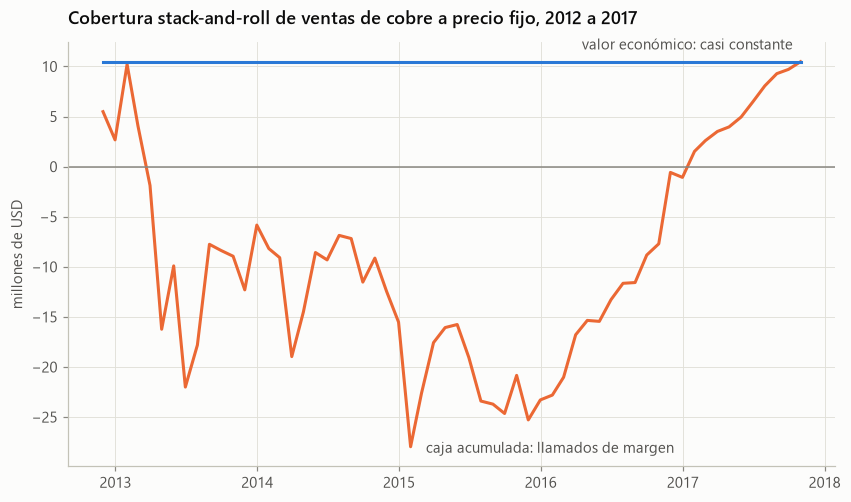

,cobre,caja acumulada,valor de los contratos pendientes,valor económico
fecha,,,,
2012-11-30,3.5800,5.4800,4.9900,10.4700
2013-11-30,3.1800,-12.3000,22.7700,10.4700
2014-11-30,3.0100,-12.4400,22.9100,10.4700
2015-11-30,2.1100,-25.2800,35.7500,10.4700
2016-11-30,2.6600,-0.5800,11.0500,10.4700
2017-10-31,3.0800,10.4700,0.0000,10.4700


In [27]:
cobre_mensual = cobre.resample("ME").last().loc["2012-10":"2017-10"]
precio_fijo = float(cobre_mensual.iloc[0]) * 1.05
meses = len(cobre_mensual) - 1
pendiente = meses * 1.0                   # millones de libras por entregar
caja, filas = 0.0, []
for t in range(1, meses + 1):
    s_ant, s = float(cobre_mensual.iloc[t - 1]), float(cobre_mensual.iloc[t])
    margen = pendiente * (s - s_ant)       # futuros largos por el volumen pendiente
    entrega = 1.0 * (precio_fijo - s)      # vende un millón de libras al precio fijo, comprado al spot
    pendiente -= 1.0
    caja += margen + entrega
    valor_compromisos = pendiente * (precio_fijo - s)
    filas.append({"fecha": cobre_mensual.index[t], "cobre": s, "caja acumulada": caja,
                  "valor de los contratos pendientes": valor_compromisos, "valor económico": caja + valor_compromisos})
mg = pd.DataFrame(filas).set_index("fecha")
peor = mg["caja acumulada"].idxmin()
print(f"Precio fijo: {precio_fijo:.2f} USD/lb. Cobre al inicio: {cobre_mensual.iloc[0]:.2f}; mínimo: {cobre_mensual.min():.2f} en {cobre_mensual.idxmin():%m-%Y}")
print(f"Máxima necesidad de caja: {-mg['caja acumulada'].min():,.1f} millones de USD en {peor:%m-%Y}")
print(f"Valor económico al final: {mg['valor económico'].iloc[-1]:,.1f}; ganancia fija esperada desde el inicio: {meses * (precio_fijo - cobre_mensual.iloc[0]):,.1f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(mg.index, mg["caja acumulada"], color=COLORES[1], linewidth=2)
ax.plot(mg.index, mg["valor económico"], color=COLORES[0], linewidth=2)
ax.axhline(0, color=TINTA_TENUE, linewidth=1)
ax.annotate("valor económico: casi constante", (mg.index[-1], mg["valor económico"].iloc[-1]), xytext=(-5, 8),
            textcoords="offset points", ha="right", color=TINTA_SECUNDARIA)
ax.annotate("caja acumulada: llamados de margen", (peor, mg["caja acumulada"].min()), xytext=(10, -4),
            textcoords="offset points", color=TINTA_SECUNDARIA)
ax.set_ylabel("millones de USD")
ax.set_title("Cobertura stack-and-roll de ventas de cobre a precio fijo, 2012 a 2017")
fig.savefig(FIGURAS / "metallgesellschaft_cobre.png", bbox_inches="tight")
plt.show()
mg.iloc[[0, 12, 24, 36, 48, -1]].round(2)

**Lectura.**

- **El valor económico no se mueve.** Queda fijo en 10,5 millones de dólares, la ganancia pactada: lo que pierden los futuros lo ganan los contratos de entrega.
- **La caja sí se mueve.** Con el cobre cayendo de 3,49 a 2,08 dólares la libra, los llamados de margen llevan la caja acumulada a −28 millones en enero de 2015. La empresa debe financiar esas pérdidas hoy, mientras las ganancias de las entregas llegan en cinco años.
- **Es el problema de Metallgesellschaft.** En 1993, con petróleo, las pérdidas superaron los USD 1.000 millones, y la decisión de cerrar la cobertura en el peor momento convirtió un problema de caja en una pérdida realizada.
- **En la realidad hay además riesgo de base:** cuando el mercado pasa a contango, renovar los futuros cuesta, como le ocurrió a Metallgesellschaft.

### Ejercicios resueltos

**Ejercicio 9.1. El apalancamiento de LTCM** *(ejercicio propio)*

A comienzos de 1998, LTCM tenía unos USD 4.700 millones de patrimonio y USD 125.000 millones en activos. ¿Cuál era su apalancamiento? ¿Qué caída del valor de los activos borraba el patrimonio? Si la volatilidad anual de sus activos era 1%, ¿cuál era la del patrimonio?

In [28]:
patrimonio, activos = 4.7, 125.0
apalancamiento = activos / patrimonio
print(f"Apalancamiento: {apalancamiento:.1f} veces")
print(f"Caída de los activos que borra el patrimonio: 1 / {apalancamiento:.1f} = {1 / apalancamiento:.2%}")
print(f"Respuesta: una volatilidad de 1% en los activos es {apalancamiento:.0f}% en el patrimonio. El apalancamiento convierte"
      " operaciones de bajo riesgo en una apuesta de alto riesgo, y el riesgo de liquidez hace el resto.")

Apalancamiento: 26.6 veces
Caída de los activos que borra el patrimonio: 1 / 26.6 = 3.76%
Respuesta: una volatilidad de 1% en los activos es 27% en el patrimonio. El apalancamiento convierte operaciones de bajo riesgo en una apuesta de alto riesgo, y el riesgo de liquidez hace el resto.


**Ejercicio 9.2. Posición oculta de un operador** *(ejercicio propio)*

Un operador acumula sin autorización 20.000 futuros largos sobre un índice, con multiplicador de 500 yenes por punto. El índice cae 2.000 puntos. ¿Cuánto pierde? Si reporta una posición neta cercana a cero porque inventa operaciones contrarias en una cuenta falsa, ¿qué control lo habría detectado? Los datos son ilustrativos.

In [29]:
contratos, multiplicador, caida = 20_000, 500, 2_000
perdida = contratos * multiplicador * caida
print(f"Pérdida: 20.000 × 500 × 2.000 = {perdida / 1e9:,.0f} mil millones de yenes")
print("Respuesta: separar la operación del registro y la liquidación, conciliar contra la cámara de compensación"
      " y controlar las posiciones brutas, no solo las netas. Fueron las fallas de Barings y de Société Générale.")

Pérdida: 20.000 × 500 × 2.000 = 20 mil millones de yenes
Respuesta: separar la operación del registro y la liquidación, conciliar contra la cámara de compensación y controlar las posiciones brutas, no solo las netas. Fueron las fallas de Barings y de Société Générale.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

Las pérdidas de Metallgesellschaft (1993) son principalmente una lección de:

- **A.** riesgo de liquidez de fondeo y de base por un hedge stack-and-roll — futuros de corto plazo usados para cubrir compromisos de largo plazo generaron grandes margin calls.
- **B.** la ausencia total de cobertura.
- **C.** default soberano.
- **D.** fraude interno de un solo trader.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** MG cubrió contratos de entrega de petróleo a precio fijo de largo plazo con futuros de corto plazo rolados hacia adelante (stack-and-roll). Cuando el precio del petróleo cayó y el mercado entró en contango, los futuros generaron enormes margin calls (riesgo de liquidez de fondeo) y pérdidas de roll/base, forzando a deshacer el hedge con pérdida.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

La cuasi-quiebra de 1998 de Long-Term Capital Management (LTCM) ilustra principalmente los peligros de:

- **A.** el apalancamiento extremo y el riesgo de liquidez cuando las operaciones de convergencia se mueven en contra durante una huida a la calidad en todo el mercado.
- **B.** tener solo efectivo.
- **C.** fraude operacional por un trader deshonesto.
- **D.** la ausencia total de modelos cuantitativos.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** LTCM operaba trades de valor relativo (convergencia) muy apalancados suponiendo que los spreads se estrecharían. En el default ruso de 1998 y la huida a la calidad, los spreads se ampliaron, las correlaciones se dispararon, y su apalancamiento más la iliquidez forzaron pérdidas enormes — una lección de riesgo de modelo, apalancamiento y liquidez.

</details>

### Trampas frecuentes

- Metallgesellschaft es un caso de liquidez de financiamiento y riesgo de base, no de fraude.
- LTCM no quebró por un error de cálculo: sus posiciones eran grandes, apalancadas y las mismas que las de otros fondos.
- Barings y Société Générale son riesgo operacional: un operador controlaba también el registro de sus operaciones.
- Una cobertura puede ser perfecta en valor y aun así quebrar a la empresa por los llamados de margen.

## FRM-10. Anatomía de la gran crisis financiera de 2007 a 2009

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Antes.** Burbuja inmobiliaria, préstamos subprime, modelo originar para distribuir, CDO sobre tramos de MBS y calificaciones AAA para tramos que dependían de supuestos de correlación.
- **Financiamiento.** Banca en la sombra: vehículos (SIV y conduits) que financiaban activos largos con papeles comerciales cortos, y bancos de inversión muy apalancados que dependían del repo.
- **Detonantes.** La caída de los precios de las viviendas, los incumplimientos subprime, el cierre de los fondos de BNP Paribas en agosto de 2007, Bear Stearns en marzo de 2008 y Lehman Brothers en septiembre de 2008.
- **Amplificadores.** Alzas de los descuentos (*haircuts*) del repo, ventas forzadas, pérdidas marcadas a mercado, corridas a los fondos del mercado monetario y exposición de AIG por CDS.
- **Respuesta y reformas.** Rescates, inyecciones de capital (TARP) y liquidez de los bancos centrales. Después vinieron Basilea III (más capital, LCR y NSFR), Dodd-Frank, la compensación central de derivados y las pruebas de estrés supervisoras.

### Análisis avanzado: la crisis en datos

Cuatro series de la Reserva Federal de St. Louis (FRED) muestran la secuencia: los precios de las viviendas (índice Case-Shiller), la tasa de morosidad de las hipotecas, el spread TED entre la tasa interbancaria a tres meses y la tasa del Tesoro, y el índice de volatilidad VIX. La franja gris es la recesión de diciembre de 2007 a junio de 2009.

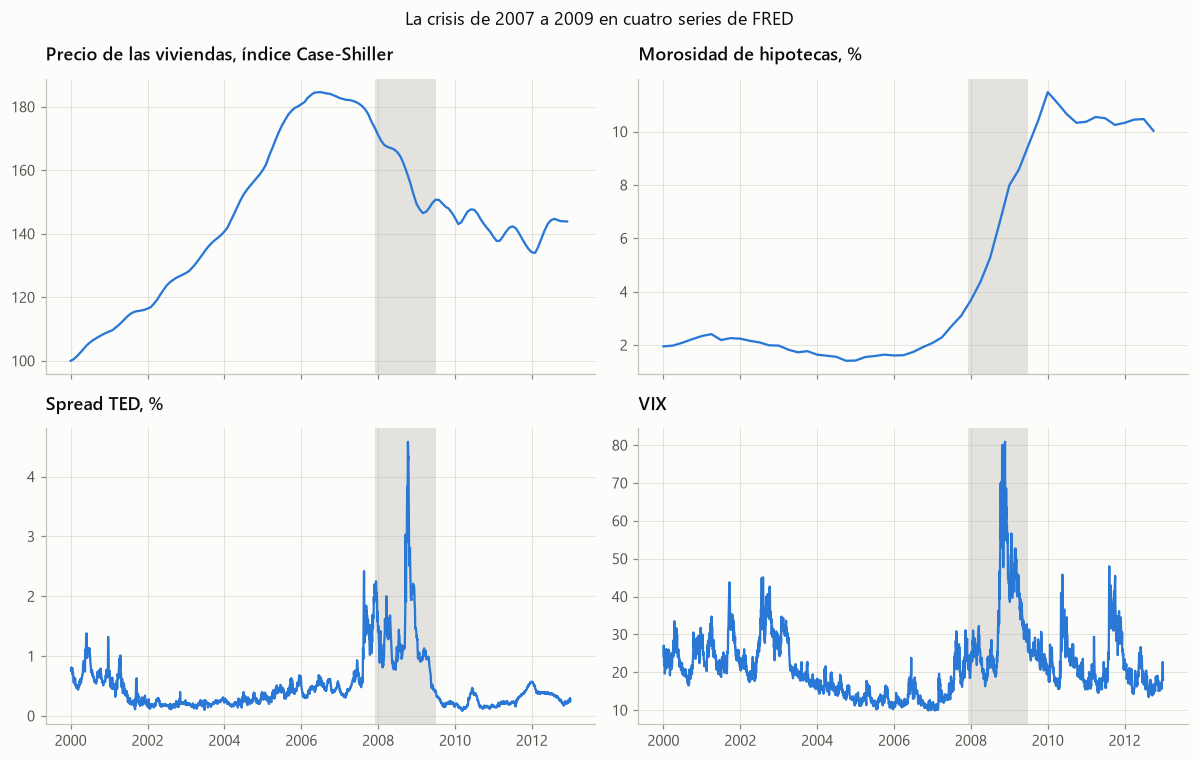

,valor
máximo del precio de las viviendas,07-2006
caída hasta el mínimo,-27.4% (02-2012)
morosidad hipotecaria máxima,11.48% (01-2010)
spread TED máximo,4.58% (10-10-2008)
VIX máximo,80.9 (20-11-2008)


In [30]:
series_fred = {"CSUSHPINSA": "Precio de las viviendas, índice Case-Shiller", "DRSFRMACBS": "Morosidad de hipotecas, %",
               "TEDRATE": "Spread TED, %", "VIXCLS": "VIX"}
fred = {s: datos.cargar_fred(s, DATOS / "fred").loc["2000":"2012"] for s in series_fred}

fig, ejes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (codigo, titulo) in zip(ejes.ravel(), series_fred.items()):
    serie = fred[codigo]
    ax.axvspan(pd.Timestamp("2007-12-01"), pd.Timestamp("2009-06-30"), color=NEUTRO, alpha=0.35, linewidth=0)
    ax.plot(serie.index, serie, color=COLORES[0], linewidth=1.5)
    ax.set_title(titulo)
fig.suptitle("La crisis de 2007 a 2009 en cuatro series de FRED")
fig.tight_layout()
fig.savefig(FIGURAS / "crisis_2008.png", bbox_inches="tight")
plt.show()

hpi = fred["CSUSHPINSA"]
maximo_hpi = hpi.loc[:"2008"].idxmax()
minimo_hpi = hpi.loc[maximo_hpi:].idxmin()
hitos = pd.Series({
    "máximo del precio de las viviendas": f"{maximo_hpi:%m-%Y}",
    "caída hasta el mínimo": f"{hpi[minimo_hpi] / hpi[maximo_hpi] - 1:.1%} ({minimo_hpi:%m-%Y})",
    "morosidad hipotecaria máxima": f"{fred['DRSFRMACBS'].max():.2f}% ({fred['DRSFRMACBS'].idxmax():%m-%Y})",
    "spread TED máximo": f"{fred['TEDRATE'].max():.2f}% ({fred['TEDRATE'].idxmax():%d-%m-%Y})",
    "VIX máximo": f"{fred['VIXCLS'].max():.1f} ({fred['VIXCLS'].idxmax():%d-%m-%Y})",
})
hitos.to_frame("valor")

**Lectura.** El orden de los eventos importa:

- **Primero se corrigió el activo.** Los precios de las viviendas tocaron su máximo en julio de 2006, más de un año antes de la recesión, y cayeron 27% hasta febrero de 2012.
- **Después se tensionó el financiamiento.** El spread TED tuvo un primer salto en agosto de 2007, cuando se cerraron los fondos de BNP Paribas, y su máximo de 4,58% el 10 de octubre de 2008, semanas después de la quiebra de Lehman.
- **La volatilidad se disparó al final.** El VIX llegó a 80,9 el 20 de noviembre de 2008.
- **Los incumplimientos llegaron tarde.** La morosidad hipotecaria subió de menos de 2% a 11,5% en enero de 2010, después del fin de la recesión. El deterioro del crédito es lento, y por eso las pruebas de estrés de crédito usan horizontes de varios años.

### Ejercicios resueltos

**Ejercicio 10.1. Descuentos del repo y desapalancamiento forzado** *(ejercicio propio)*

Un banco de inversión financia bonos con repo. Si el descuento (haircut) es h, cada peso de patrimonio sostiene como máximo 1/h pesos de activos. Con un patrimonio de 10, ¿cuántos activos puede mantener si el descuento sube de 2% a 10% y a 25%? ¿Cuántos activos debe vender?

In [31]:
patrimonio_ej = 10.0
filas = {}
for h in (0.02, 0.10, 0.25):
    filas[f"{h:.0%}"] = {"apalancamiento máximo": 1 / h, "activos máximos": patrimonio_ej / h}
tabla_repo = pd.DataFrame(filas).T
tabla_repo["ventas forzadas desde 2%"] = tabla_repo["activos máximos"].iloc[0] - tabla_repo["activos máximos"]
print(tabla_repo.round(1).to_string())
print("Respuesta: de 500 a 100 y a 40 en activos. Si todos venden a la vez, los precios caen, el patrimonio"
      " baja y los descuentos suben de nuevo: la espiral de liquidez de 2008.")

     apalancamiento máximo  activos máximos  ventas forzadas desde 2%
2%                 50.0000         500.0000                    0.0000
10%                10.0000         100.0000                  400.0000
25%                 4.0000          40.0000                  460.0000
Respuesta: de 500 a 100 y a 40 en activos. Si todos venden a la vez, los precios caen, el patrimonio baja y los descuentos suben de nuevo: la espiral de liquidez de 2008.


**Ejercicio 10.2. Tramos sobre tramos** *(ejercicio propio)*

Un pool de hipotecas pierde 12%. Un tramo mezzanine de 5% a 15% del pool, ¿cuánto pierde? Una CDO se arma con 100 tramos mezzanine como ese, de pools distintos pero con la misma pérdida, y emite un tramo senior de 30% a 100%. ¿Cuánto pierde?

In [32]:
perdida_pool = 0.12
perdida_mezz = float(fa.perdida_tramo(perdida_pool, 0.05, 0.15))
perdida_cdo = perdida_mezz
perdida_senior = float(fa.perdida_tramo(perdida_cdo, 0.30, 1.00))
print(f"Tramo mezzanine: (12% - 5%) / 10% = {perdida_mezz:.0%} de pérdida")
print(f"Tramo senior de la CDO: ({perdida_cdo:.0%} - 30%) / 70% = {perdida_senior:.0%} de pérdida")
print("Respuesta: una pérdida de 12% en las hipotecas destruye 70% del mezzanine y 57% de un tramo senior de la CDO"
      " que parecía protegido. Cuando los pools caen juntos, la subordinación desaparece.")

Tramo mezzanine: (12% - 5%) / 10% = 70% de pérdida
Tramo senior de la CDO: (70% - 30%) / 70% = 57% de pérdida
Respuesta: una pérdida de 12% en las hipotecas destruye 70% del mezzanine y 57% de un tramo senior de la CDO que parecía protegido. Cuando los pools caen juntos, la subordinación desaparece.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un motor central de la crisis financiera de 2007–2009 fue:

- **A.** tenencias excesivas de bonos soberanos libres de riesgo.
- **B.** una escasez de derivados.
- **C.** el modelo originar-para-distribuir de hipotecas subprime, el alto apalancamiento y los productos securitizados mal valuados cuyos riesgos se subestimaron.
- **D.** estándares de préstamo demasiado conservadores.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Los prestamistas originaban préstamos subprime riesgosos para venderlos (originate-to-distribute), empaquetándolos en securitizaciones calificadas con demasiada indulgencia. Combinado con alto apalancamiento, fondeo de corto plazo y débil suscripción, la caída de los precios de las viviendas gatilló pérdidas en cascada y una crisis de liquidez/solvencia.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

El sistema de "banca en la sombra" (shadow banking) contribuye al riesgo sistémico porque:

- **A.** está totalmente asegurado por las garantías de depósitos.
- **B.** realiza transformación de plazos/liquidez similar a la bancaria (p. ej., fondos money-market, SPVs, repo) fuera del sistema bancario regulado y sus redes de seguridad.
- **C.** no tiene apalancamiento.
- **D.** mantiene solo efectivo.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Los bancos en la sombra (fondos money-market, conductos ABCP, mercados repo, SPVs) proveen crédito y transforman plazos como los bancos pero sin seguro de depósitos ni respaldo del banco central. Esto los hace propensos a corridas, como se vio en 2008, amplificando el riesgo sistémico.

</details>

### Trampas frecuentes

- La crisis no la causó un solo factor: fue la combinación de crédito malo, apalancamiento y financiamiento de corto plazo.
- La banca en la sombra transformaba plazos sin seguro de depósitos ni acceso regular al banco central.
- Un tramo AAA de una CDO de tramos mezzanine no se parece a un bono AAA: es muy sensible a la correlación.
- El spread TED mide la tensión de financiamiento entre bancos, no el riesgo de crédito de las empresas.

## FRM-11. Código de conducta de GARP

*Relevancia en el examen: alta. Dificultad: básica.*

### Idea central

El código tiene principios y estándares profesionales:

| Sección | Contenido |
|---|---|
| Integridad profesional y conducta ética | Actuar con honestidad, integridad y competencia; no participar en conductas engañosas ni fraudulentas |
| Conflictos de interés | Revelar los conflictos reales o potenciales y evitar que afecten el juicio profesional |
| Confidencialidad | No usar información confidencial en beneficio propio ni revelarla sin autorización |
| Responsabilidades fundamentales | Conocer y cumplir las leyes y regulaciones; no participar en violaciones de otros |
| Mejores prácticas generales | Aplicar un juicio profesional independiente y reconocer las limitaciones de los modelos y los datos |

Las violaciones pueden llevar a la suspensión o expulsión de la membresía de GARP y a la revocación del derecho a usar la designación FRM. Si una ley local es más exigente que el código, se aplica la ley; si el código es más exigente, se aplica el código.

### Dilemas resueltos

Este capítulo es cualitativo, así que los ejercicios son casos con su resolución.

1. **Un gerente presiona para bajar un VaR.** Tu jefe te pide cambiar el período de datos para que el VaR quede bajo el límite antes del comité. *Resolución:* es manipular un modelo para engañar al comité; viola la integridad profesional. Se rechaza el cambio, se documenta y se escala por los canales internos: riesgos, cumplimiento o auditoría. Si esos canales fallan, se evalúa escalar a instancias externas.
2. **Un regalo de un proveedor.** Un proveedor de datos que está en licitación te invita a un viaje. *Resolución:* es un conflicto de interés que puede afectar tu independencia. Se revela y se rechaza si puede influir en la decisión.
3. **Información de tu empleador anterior.** Llegas a un banco nuevo con los modelos de tu empleador anterior en un pendrive. *Resolución:* usarlos viola la confidencialidad y probablemente la ley. No se usan.
4. **Limitaciones del modelo.** Validaste un modelo de riesgo de crédito que funciona mal con deudores nuevos, pero el negocio quiere usarlo igual. *Resolución:* la buena práctica exige comunicar las limitaciones de forma clara y por escrito, y proponer ajustes o restricciones de uso.

### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

Bajo el Código de Conducta de GARP, un profesional de riesgos que toma conocimiento de una conducta poco ética de un colega debería PRIMERO:

- **A.** Abordarlo internamente por los canales apropiados antes de escalarlo externamente
- **B.** Ignorarlo si no afecta directamente su propio trabajo
- **C.** Reportarlo de inmediato a los reguladores
- **D.** Divulgarlo públicamente en redes profesionales

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** El Código de GARP exige que los profesionales aborden las preocupaciones éticas primero por los canales internos apropiados. El escalamiento externo (a reguladores, etc.) puede justificarse si los canales internos fallan o son cómplices, pero el reporte interno va primero.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad básica)*

¿Cuál de las siguientes acciones violaría más claramente el Código de Conducta de GARP?

- **A.** Reportar una limitación de un modelo de riesgo a la alta dirección
- **B.** Asistir a una conferencia pública de un competidor
- **C.** Recomendar límites de riesgo conservadores
- **D.** Usar información privilegiada para operar valores

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Operar con información material, no pública (privilegiada) es ilegal y viola el Código de GARP, que exige integridad y cumplimiento de todas las leyes aplicables. Las demás opciones son requeridas o permisibles.

</details>

### Trampas frecuentes

- El primer paso ante una conducta indebida suele ser escalar por los canales internos apropiados, no ir directo al regulador ni a la prensa.
- Revelar un conflicto de interés no siempre basta: si compromete el juicio, hay que abstenerse.
- Cuando la ley local y el código difieren, se aplica el estándar más estricto.
- Las sanciones las decide GARP e incluyen revocar la designación FRM.

## Resumen del libro

- **La correlación manda.** Aparece en el capital de una cartera de crédito, en el valor de los tramos de una CDO, en la suma de los límites y en el beneficio de diversificación del capital económico. En estrés sube, y lo que parecía diversificado deja de serlo.
- **Cubrirse crea valor solo por imperfecciones del mercado,** como los impuestos convexos o los costos de quiebra, y puede crear riesgo de liquidez.
- **Las carteras óptimas son frágiles:** el error de estimación de las medias domina a la teoría.
- **Los desastres se repiten** con los mismos ingredientes: apalancamiento, concentración, liquidez, incentivos y controles débiles.